# **Cети c Обратными Связями**

# 1.1 Сеть Хопфилда

https://github.com/ccd97/hello_nn/blob/master/Hopfield-Network/np_hnn_reconstruction.ipynb

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

функция для отображения символов

In [ ]:
def plot_images(images, title, no_i_x, no_i_y=3):
    fig = plt.figure(figsize=(10, 15))
    # fig.set_title(title)
    images = np.array(images).reshape(-1, 5, 5)
    images = np.pad(images, ((0, 0), (1, 1), (1, 1)), 'constant', constant_values=-1)
    for i in range(no_i_x):
        for j in range(no_i_y):
            ax = fig.add_subplot(no_i_x, no_i_y, no_i_x * j + (i + 1))
            ax.matshow(images[no_i_x * j + i], cmap="gray")
            plt.xticks(np.array([]))
            plt.yticks(np.array([]))

            if j == 0 and i == 0:
                ax.set_title("исходный")
            elif j == 0 and i == 1:
                ax.set_title("искажение")
            elif j == 0 and i == 2:
                ax.set_title("реконструкция")

Коды символов

In [ ]:
perfect_data = {
    "P": [1, 1, 1, 1, -1, 1, -1, -1, -1, 1, 1, 1, 1, 1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1],
    "Y": [1, -1, -1, -1, 1, -1, 1, -1, 1, -1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1],
    "T": [1, 1, 1, 1, 1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1],
    "H": [1, -1, -1, -1, 1, 1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, 1, 1, -1, -1, -1, 1],
    "O": [1, 1, 1, 1, 1, 1, -1, -1, -1, 1, 1, -1, -1, -1, 1, 1, -1, -1, -1, 1, 1, 1, 1, 1, 1],
    "N": [1, -1, -1, -1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, 1, 1, -1, -1, -1, 1]
}

### **число нейронов**
0.138 * n_neurons = 0.138 * 25 = 3.45 ~ 3

In [ ]:

n_train = 3
n_test = 100


#число выводимых ответов
n_train_disp = 10

#коэффициент искажения (0 < distort < 1)
distort = 0.1

#рзмер картинки(width)
n_side = 5

#число нейронов
n_neurons = n_side * n_side

In [ ]:
train_data = [np.array(d) for d in perfect_data.values()][:n_train]

Строим тестовые данные с шумом

In [ ]:
test_data = []
for d in range(n_test):
    r_i = np.random.randint(0, n_train)
    base_pattern = np.array(train_data[r_i])
    noise = 1 * (np.random.random(base_pattern.shape) > distort)
    np.place(noise, noise == 0, -1)
    noisy_pattern = np.multiply(base_pattern, noise)
    test_data.append((base_pattern, noisy_pattern))

In [ ]:
noise

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,
        1,  1, -1,  1,  1,  1,  1,  1])

In [ ]:
test_data[0]

(array([ 1,  1,  1,  1, -1,  1, -1, -1, -1,  1,  1,  1,  1,  1, -1,  1, -1,
        -1, -1, -1,  1, -1, -1, -1, -1]),
 array([ 1,  1, -1,  1, -1,  1, -1, -1, -1,  1,  1,  1,  1,  1, -1,  1,  1,
         1,  1, -1, -1, -1,  1, -1, -1]))

## 1.2 Реализация

обучение по Хеббу dW=D[i,:]''* D[i,:] ( размер число_нейронов х число_нейронов ), w(i,i)=0

In [ ]:
def train(neu, training_data):
    w = np.zeros([neu, neu])
    for data in training_data:
        w += np.outer(data, data)
    for diag in range(neu):
        w[diag][diag] = 0  # условие устойчивости
    return w

Тестирование

In [ ]:
def test(weights, testing_data):
    success = 0.0

    output_data = []

    for data in testing_data:
        true_data = data[0]
        noisy_data = data[1]
        predicted_data = retrieve_pattern(weights, noisy_data)
        if np.array_equal(true_data, predicted_data):
            success += 1.0
        output_data.append([true_data, noisy_data, predicted_data])

    return (success / len(testing_data)), output_data

функция сети (step шагов моделирования переходного процесса)

In [ ]:
def retrieve_pattern(weights, data, steps=5):
    res = np.array(data)

    for _ in range(steps):
        for i in range(len(res)):
            raw_v = np.dot(weights[i], res)
            # пороговый нейрон
            if raw_v > 0:
                res[i] = 1
            else:
                res[i] = -1
    return res

Обучаем

In [ ]:
W = train(n_neurons, train_data)

Тестим

In [ ]:
accuracy, op_imgs = test(W, test_data)
print("accuracy сети на тестовых примерах %f" % (accuracy ))

accuracy сети на тестовых примерах 0.990000


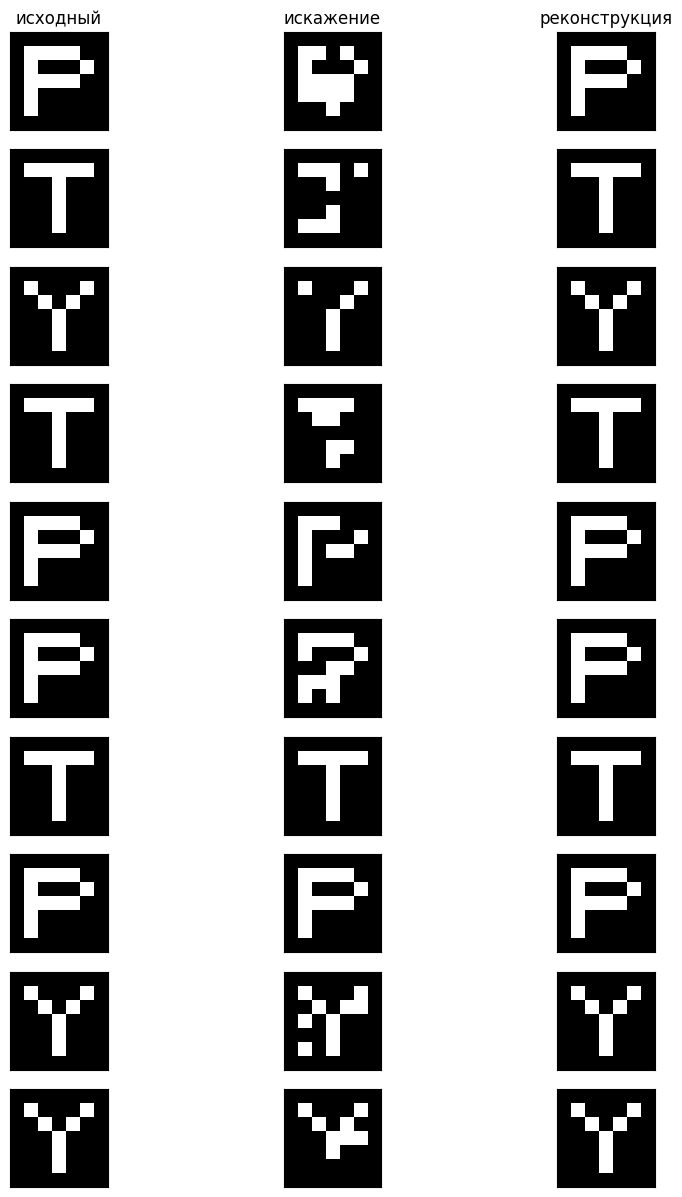

In [ ]:
plot_images(op_imgs, "Reconstructed Data", n_train_disp)
plt.show()

## Задание 1.

    1.1 построить связь числа эталонов и качества ответа (n_train)

    1.2 построить связь размера зашумления с качеством ответа (distort)

    1.3 посмотреть ответ на разных шага (step)

n_train = 1, accuracy = 1.000
n_train = 2, accuracy = 1.000
n_train = 3, accuracy = 0.985
n_train = 4, accuracy = 0.685
n_train = 5, accuracy = 0.460
n_train = 6, accuracy = 0.155


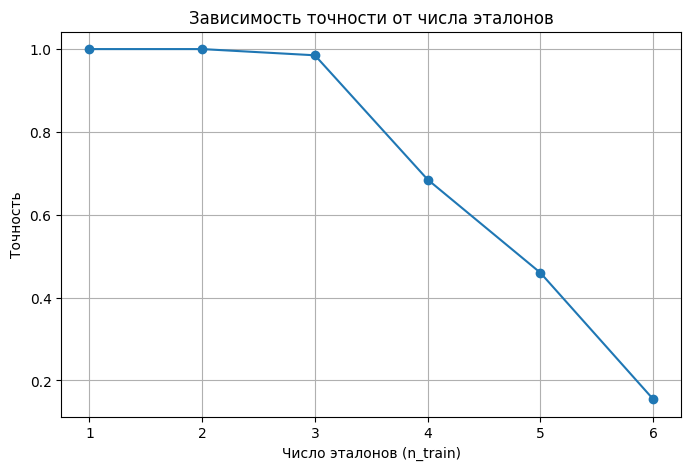

In [ ]:
n_train_values = list(range(1, 7))
accuracies_n_train = []
n_test = 200
distort = 0.1
n_side = 5
n_neurons = n_side * n_side

for n_tr in n_train_values:
    train_data = [np.array(d) for d in perfect_data.values()][:n_tr]
    test_data = []
    for _ in range(n_test):
        r_i = np.random.randint(0, n_tr)
        base_pattern = np.array(train_data[r_i])
        noise = 1 * (np.random.random(base_pattern.shape) > distort)
        np.place(noise, noise == 0, -1)
        noisy_pattern = np.multiply(base_pattern, noise)
        test_data.append((base_pattern, noisy_pattern))
    W = train(n_neurons, train_data)
    acc, _ = test(W, test_data)
    accuracies_n_train.append(acc)
    print(f"n_train = {n_tr}, accuracy = {acc:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(n_train_values, accuracies_n_train, 'o-')
plt.xlabel('Число эталонов (n_train)')
plt.ylabel('Точность')
plt.title('Зависимость точности от числа эталонов')
plt.grid(True)
plt.show()

Точность при увеличинии числа эталонов падает, так как они как бы будут накладываться друг на друга

distort = 0.00, accuracy = 1.000
distort = 0.05, accuracy = 1.000
distort = 0.10, accuracy = 0.975
distort = 0.15, accuracy = 0.920
distort = 0.20, accuracy = 0.880
distort = 0.25, accuracy = 0.725
distort = 0.30, accuracy = 0.715
distort = 0.35, accuracy = 0.545
distort = 0.40, accuracy = 0.365
distort = 0.45, accuracy = 0.295
distort = 0.50, accuracy = 0.140


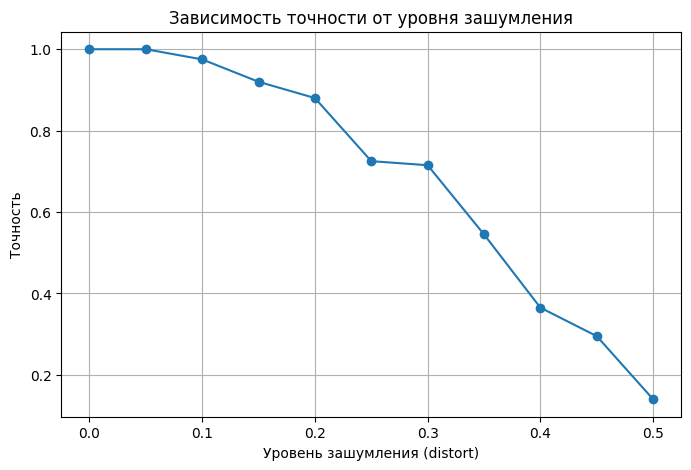

In [ ]:
n_train = 3
distort_values = np.linspace(0, 0.5, 11)
accuracies_distort = []
n_test = 200

train_data = [np.array(d) for d in perfect_data.values()][:n_train]
W = train(n_neurons, train_data)

for dist in distort_values:
    test_data = []
    for _ in range(n_test):
        r_i = np.random.randint(0, n_train)
        base_pattern = np.array(train_data[r_i])
        noise = 1 * (np.random.random(base_pattern.shape) > dist)
        np.place(noise, noise == 0, -1)
        noisy_pattern = np.multiply(base_pattern, noise)
        test_data.append((base_pattern, noisy_pattern))
    acc, _ = test(W, test_data)
    accuracies_distort.append(acc)
    print(f"distort = {dist:.2f}, accuracy = {acc:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(distort_values, accuracies_distort, 'o-')
plt.xlabel('Уровень зашумления (distort)')
plt.ylabel('Точность')
plt.title('Зависимость точности от уровня зашумления')
plt.grid(True)
plt.show()

тут ожидаемо, что сильное зашумление сильно понизит точность, картинку сложнее востановить

steps = 1, accuracy = 0.965
steps = 2, accuracy = 0.985
steps = 3, accuracy = 0.985
steps = 4, accuracy = 0.985
steps = 5, accuracy = 0.985
steps = 6, accuracy = 0.985
steps = 7, accuracy = 0.985
steps = 8, accuracy = 0.985
steps = 9, accuracy = 0.985
steps = 10, accuracy = 0.985


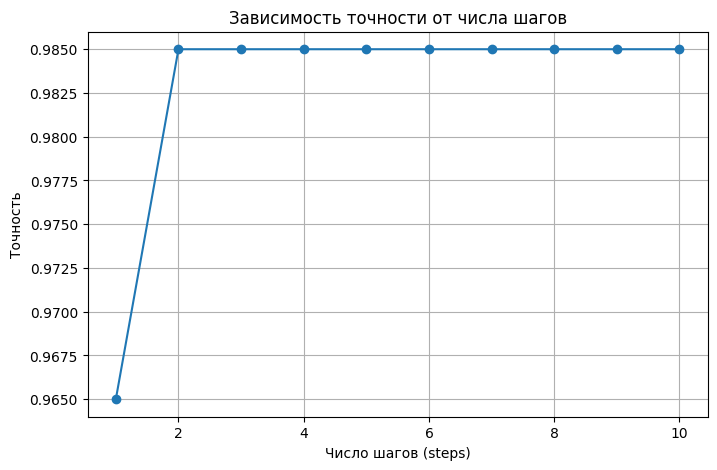

In [ ]:
n_train = 3
distort = 0.1
n_test = 200
steps_values = list(range(1, 11))
accuracies_steps = []

train_data = [np.array(d) for d in perfect_data.values()][:n_train]
W = train(n_neurons, train_data)

test_data = []
for _ in range(n_test):
    r_i = np.random.randint(0, n_train)
    base_pattern = np.array(train_data[r_i])
    noise = 1 * (np.random.random(base_pattern.shape) > distort)
    np.place(noise, noise == 0, -1)
    noisy_pattern = np.multiply(base_pattern, noise)
    test_data.append((base_pattern, noisy_pattern))

for steps in steps_values:
    success = 0
    for true_data, noisy_data in test_data:
        predicted = retrieve_pattern(W, noisy_data, steps=steps)
        if np.array_equal(true_data, predicted):
            success += 1
    acc = success / len(test_data)
    accuracies_steps.append(acc)
    print(f"steps = {steps}, accuracy = {acc:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(steps_values, accuracies_steps, 'o-')
plt.xlabel('Число шагов (steps)')
plt.ylabel('Точность')
plt.title('Зависимость точности от числа шагов')
plt.grid(True)
plt.show()

достаточно сделать 2 шага обучения, дальше улучшений не будет

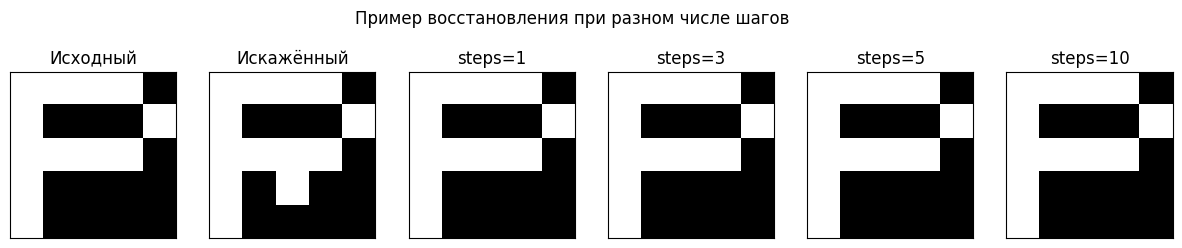

In [ ]:
r_i = 0
base = np.array(train_data[r_i])
noise = 1 * (np.random.random(base.shape) > distort)
np.place(noise, noise == 0, -1)
noisy = np.multiply(base, noise)

steps_to_show = [1, 3, 5, 10]
patterns = [base, noisy] + [retrieve_pattern(W, noisy, steps=s) for s in steps_to_show]
titles = ['Исходный', 'Искажённый'] + [f'steps={s}' for s in steps_to_show]

fig, axes = plt.subplots(1, len(patterns), figsize=(15, 3))
for ax, pat, title in zip(axes, patterns, titles):
    ax.matshow(pat.reshape(5, 5), cmap='gray')
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle('Пример восстановления при разном числе шагов')
plt.show()

# RNN

# 2.1 Рекурентные сети для обработки последовательностей

что знаем про обработку текстов:
- Компьютер не понимает текст, поэтому нам нужно его как-то закодировать - представить в виде вектора
- В тексте много повторяющихся слов/лишний слов - нужно сделать препроцессинг:
    - удалить знаки препинания
    - удалить стоп-слова
    - привести слова к начальной форме (**стемминг** и **лемматизация**)
    - ???
    
    
- После этого можем представить наш текст (набор слов) в виде вектора, например, стандартными способами:
    - **CounterEncoding** - вектор длины размер нашего словаря
        - есть словарь vocab, который можем включать слова, ngram-ы
        - каждому документу $doc$ ставим в соответствие вектор $vec\ :\ vec[i]=1,\ если\ vocab[i]\ \in\ doc$
    - **HashingVectorizer** - вектор заранее заданной длины
        - каждому документу $doc$ ставим в соответствие вектор $vec\ :\ vec[i]=1,\ если\ \exists\ txt\ \in\ doc:\ hash(text)\ =\ i$
    - **TfIdfVectorizer** - вектор длины размер нашего словаря
        - есть словарь vocab, который можем включать слова, ngram-ы
        - каждому документу $doc$ ставим в соответствие вектор $vec\ :\ vec[i]=tf(vocab[i])*idf(vocab[i]),\ если\ vocab[i]\ \in\ doc$
    
        $$ tf(t,\ d)\ =\ \frac{n_t}{\sum_kn_k} $$
        $$ idf(t,\ D)\ =\ \log\frac{|D|}{|\{d_i\ \in\ D|t\ \in\ D\}|} $$
        
, где
- $n_t$ - число вхождений слова $t$ в документ, а в знаменателе — общее число слов в данном документе
- $|D|$ — число документов в коллекции;
- $|\{d_i\ \in\ D\mid\ t\in d_i\}|$— число документов из коллекции $D$, в которых встречается $t$ (когда $n_t\ \neq\ 0$).



Это база и она работает. Есть более продвинутые подходы: эмбединги . Но любой текст - это последовательность, и работают с ним как с последовательностью. нужна архитектура, которая будет работать с текстом как с последовательностью, двигаясь по эмбедингам и как-то меняя их значения.

Возьмем перцептрон с входом - эмбедингом слова (пусть пока он фиксированный) и будем пытаться классифицировать каждое слово.

Почему классифицировать? потому что это частая задача в обработке языка + это дает возможность генерировать текст (просто классифицируем на кол-во классов = кол-ву слов в словаре).

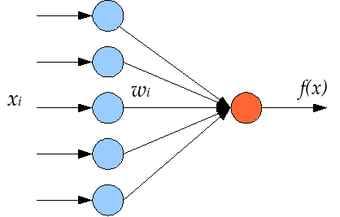


Какая тут последовательность? никакой, но давайте на вход подавать эмбединг, но в 1 скрытый слой будем добавлять последний скрытый слой предыдущего шага)

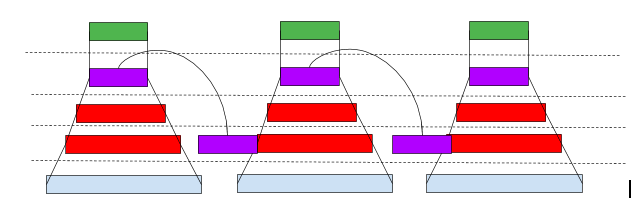

То есть прокидываем информацию с предыдущего шага, а за счет того, что мы все время так объединяем вектора получаем то, что информация проходит через текст от начала до конца. Что делать с 1 шагом? -> Добавим вектор из нулей. И вот мы получили первую рекурентную сеть. Чаще её рисуют следующим образом:


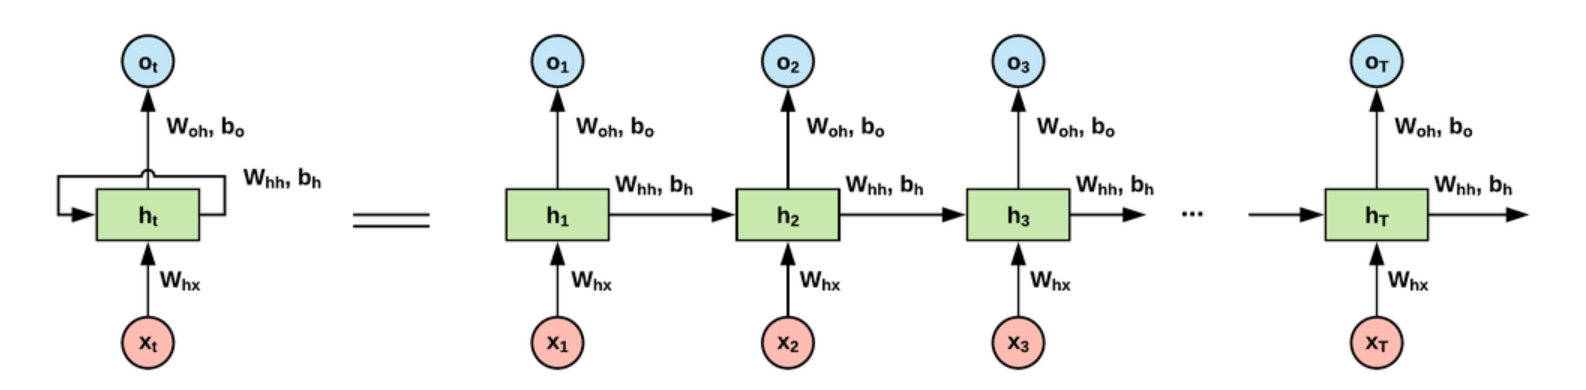


Итак, построили простую рекуретную сеть. как её обучать?

Как и в MLP - градиентным спуском, нам нужно двигаться во времени и обновлять параметры, поэтому обучение таких сетей занимает очень много времени (вы не можете обновить веса для 1-го токена, пока не посчитаете градиент сквозь время).

Тренируем такую систему, где промежуточный выход с сети прошлого шага дают на вход сети на следующем шаге. Это значит, что она может выучить некоторое  представление входа.

## 2.2 как это в коде:

class RNN:

  # ...
  
  def step(self, x):
  
    # update the hidden state
    
    self.h = np.tanh(np.dot(self.W_hh, self.h) + np.dot(self.W_xh, x))
    
    # compute the output vector
    
    y = np.dot(self.W_hy, self.h)
    
    return y


forward, прямой проход. Он выглядит следующим образом:  

- матричное произведение весов W и текущего состояния h
- добавляем тоже произведение весов W на вход x.
- получаем новый h.


- Есть набор X, где t - элементы последовательности.
- сливаем h и X_t вместе, прогоняем через слой, через функцию активации. и получаем следующие h.

## 2.3 Количество слоев

Можно так же настэкать большое количество слоев, как и везде.
Вот так выглядит рекурентная сеть с несколькими слоями:

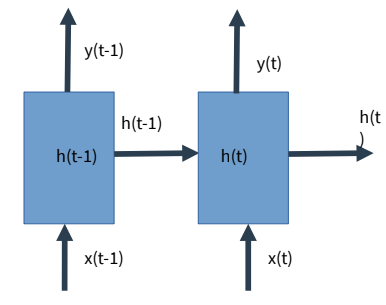
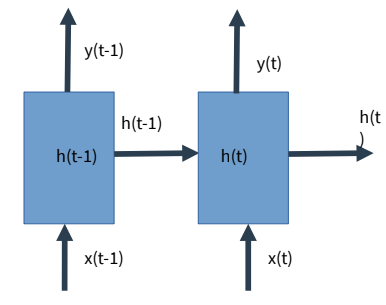

То есть обычным образом можно прогнать сигнал через слои сети. И при этом каждый из слоев выдает своему эквивалентному слою в следующей итерации сети некоторое скрытое состояние. Чем больше слоев, тем сеть обладает большей обобщающей способностью. И каждый слой на своем уровне понимания может себе в будущем передать состояние. При этом веса у каждого эквивалентного слоя одни и те же.


## 2.4 Варианты связей

Что делать, если мы хотим классифицировать текст целиком? оставить только последний выход!

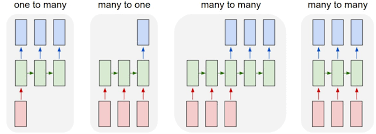

## 2.5 Реализация

y — необработанные входные данные нейронной сети;

р — конечная вероятность: р = softmax(y);

с — истинная метка определенного образца текста, так называемый «правильный» класс;

L — потеря перекрестной энтропии: L = -ln(pc);

Wxh, Whh и Why — три матрицы веса в рассматриваемой нейронной сети;

bh и by — два вектора смещения в рассматриваемой рекуррентной нейронной сети RNN.

(реализация модели в классе Python на https://python-scripts.com/recurrent-neural-network) https://gist.github.com/karpathy/d4dee566867f8291f086


In [ ]:
# данные для работы высказывания плохо\хорошо (0\1) - основной класс 0
train_data = {
  'good': True,
  'bad': False,
  'happy': True,
  'sad': False,
  'not good': False,
  'not bad': True,
  'not happy': False,
  'not sad': True,
  'very good': True,
  'very bad': False,
  'very happy': True,
  'very sad': False,
  'i am happy': True,
  'this is good': True,
  'i am bad': False,
  'this is bad': False,
  'i am sad': False,
  'this is sad': False,
  'i am not happy': False,
  'this is not good': False,
  'i am not bad': True,
  'this is not sad': True,
  'i am very happy': True,
  'this is very good': True,
  'i am very bad': False,
  'this is very sad': False,
  'this is very happy': True,
  'i am good not bad': True,
  'this is good not bad': True,
  'i am bad not good': False,
  'i am good and happy': True,
  'this is not good and not happy': False,
  'i am not at all good': False,
  'i am not at all bad': True,
  'i am not at all happy': False,
  'this is not at all sad': True,
  'this is not at all happy': False,
  'i am good right now': True,
  'i am bad right now': False,
  'this is bad right now': False,
  'i am sad right now': False,
  'i was good earlier': True,
  'i was happy earlier': True,
  'i was bad earlier': False,
  'i was sad earlier': False,
  'i am very bad right now': False,
  'this is very good right now': True,
  'this is very sad right now': False,
  'this was bad earlier': False,
  'this was very good earlier': True,
  'this was very bad earlier': False,
  'this was very happy earlier': True,
  'this was very sad earlier': False,
  'i was good and not bad earlier': True,
  'i was not good and not happy earlier': False,
  'i am not at all bad or sad right now': True,
  'i am not at all good or happy right now': False,
  'this was not happy and not good earlier': False,
}

test_data = {
  'this is happy': True,
  'i am good': True,
  'this is not happy': False,
  'i am not good': False,
  'this is not bad': True,
  'i am not sad': True,
  'i am very good': True,
  'this is very bad': False,
  'i am very sad': False,
  'this is bad not good': False,
  'this is good and happy': True,
  'i am not good and not happy': False,
  'i am not at all sad': True,
  'this is not at all good': False,
  'this is not at all bad': True,
  'this is good right now': True,
  'this is sad right now': False,
  'this is very bad right now': False,
  'this was good earlier': True,
  'i was not happy and not good earlier': False,
}



In [ ]:
# Создание словаря
vocab = list(set([w for text in train_data.keys() for w in text.split(' ')]))
vocab_size = len(vocab)

print('%d unique words found' % vocab_size) # найдено 18 уникальных слов
# Назначить индекс каждому слову
word_to_idx = { w: i for i, w in enumerate(vocab) }
idx_to_word = { i: w for i, w in enumerate(vocab) }

print(word_to_idx['good']) # индекс
print(idx_to_word[0]) # слово

18 unique words found
12
am


In [ ]:


# делаем one-hot-encoding для слов текста по каждому слову в список
def createInputs(text):
    #Возвращает массив слова в введенной строке текста
    #   - текст является строкой string
    #   - вектор имеет форму (vocab_size, 1)

    inputs = []
    for w in text.split(' '):
        v = np.zeros((vocab_size, 1))
        v[word_to_idx[w]] = 1.0
        inputs.append(v)
    #print(len(inputs))
    return inputs

hidden_size_=3
# Классическая рекуррентная нейронная сеть
input_size_=vocab_size
output_size_=1

def init( input_size=vocab_size, output_size=1, hidden_size=hidden_size_):
        # Вес
        #print(input_size,output_size, hidden_size)
        # задаем начальные значения весов и сдвигов (они маленькие и случайные)
        Whh = np.random.randn(hidden_size, hidden_size) / 1000
        Wxh = np.random.randn(hidden_size, input_size) / 1000
        Why = np.random.randn(output_size, hidden_size) / 1000
        #print(Whh.shape, Wxh.shape,Why.shape)
        # Сдвиги
        bh = np.zeros((hidden_size, 1))
        by = np.zeros((output_size, 1))
        return Whh,Wxh,Why,by,bh

# ПРЯМОЙ ПРОХОД
def forward( inputs=None,  Whh=None,Wxh=None,Why=None, by=None, bh=None, i=None):
        #Выполнение передачи нейронной сети при помощи входных данных
        #Возвращение результатов вывода  и скрытого состояния(y,h),
        # сохранем значения h по узлам в last_hs
        #hidden_size_=3

        #print('Whh:',Whh)
        # инициализируемм сеть для нового примерва - очистка памяти сети
        h = np.zeros((Whh.shape[0], 1))
        #print('h=',h)
        # запускаем новый пример
        last_inputs = inputs
        # сохраняем первое скрытое состояние (самое старое)
        last_hs = { 0: h }
        # тут смотреть как выглядит пример
        #for j in range(len(inputs)):
        #    print(inputs[j].T)
        # Выполнение каждого шага нейронной сети RNN
        for i, x in enumerate(inputs):
            # для каждого примера-предложения отдельно (никаких пакетов)
            # вычисляем скрытое состояние
            h = np.tanh(np.dot(Wxh , x) + np.dot(Whh , h) + bh)
            # записываем его значение в следующую позицию для сохранения
            last_hs[i + 1] = h
            # тоже посмотреть как все движется
            #print('i=',i,'x=',x.T)
            #print('last_h=',last_hs[i+1].T)
            #last_hs
        # вычисляем выхода - строго по формуле
        y = np.dot(Why , h) + by

        return y, h  , last_hs

# наша последняя функция на выходе сети (массив из 2-х выходов у - y[0] - класс 0, y[1] - класс 1  )
def softmax(xs=None):
    # Применение функции Softmax для входного массива
    return np.exp(xs)/np.sum(np.exp(xs))
# ОБРАТНОЕ РАСПРОСТРАНЕНИЕ
def backprop( last_inputs=None, last_hs=None, d_y=None, learn_rate=2e-2,Whh=None,Wxh=None,Why=None,by=None, bh=None):
        #Выполнение фазы обратного распространения нейронной сети RNN.
        #####################################
        n = len(last_inputs)# число шагов для этой последовательности
        #(в нормальных сетях выравнивается методами заполнения,
        #но мы можем делать как хотим и экономим процедуру обработки данных)

        # Вычисление dL/dWhy и dL/dby.
        d_Why = (d_y * last_hs[n].T)
        d_by = d_y

        # Инициализация dL/dWhh, dL/dWxh, и dL/dbh к нулю.
        d_Whh = np.zeros(Whh.shape)
        d_Wxh = np.zeros(Wxh.shape)
        d_bh = np.zeros(bh.shape)

        # Вычисление dL/dh для последнего h.
        d_h = np.dot(Why.T ,d_y)

        # Обратное распространение во времени
        #(идем по всем активным для данной последовательности n узлам).
        for t in reversed(range(n)):
            # считаем: dL/dh * (1 - h^2)
            temp = ((1 - last_hs[t + 1] ** 2) * d_h)

            # dL/db = dL/dh * (1 - h^2)
            d_bh += temp

            # dL/dWhh = dL/dh * (1 - h^2) * h_{t-1}
            d_Whh += temp * last_hs[t].T

            # dL/dWxh = dL/dh * (1 - h^2) * x
            d_Wxh += temp*last_inputs[t].T

            #dL/dh = dL/dh * (1 - h^2) * Whh
            d_h = np.dot(Whh, temp)

            #закончили проход узла и идем к следующем

        # можно посмотреть как отработал шаг до конца
        #print([d_Whh,d_Wxh,d_Why,d_by, d_bh])

        #ограничиваем рост (взрыв градиента) для Keras sgd = optimizers.SGD(lr=0.01, clipnorm=1.)
        for d in [d_Wxh, d_Whh, d_Why, d_bh, d_by]:
            np.clip(d, -1, 1, out=d)


        # Обновляем вес и смещение с использованием градиентного спуска
        #(все как обычно - можно брать алгоритмы с адаптацией шага и моментами).

        Whh -= learn_rate * d_Whh
        Wxh -= learn_rate * d_Wxh
        Why -= learn_rate * d_Why
        bh -= learn_rate * d_bh
        by -= learn_rate * d_by


        # вернем все параметры нашей сети

        return Whh,Wxh,Why,by, bh


In [ ]:
# переходим к запуску всего процесса целиком

# начальные ошибки и точность
loss = []
num_correct = []
loss_test = []
num_correct_test = []
inputs_=train_data
print()
target_=[]
W=[]

# Цикл для каждого примера тренировки по всем эпохам
whh, wxh, why, by, bh =init(input_size=vocab_size, output_size=2, hidden_size=hidden_size_)
last_hs=np.zeros(bh.shape)
# по эпохам
for epoch in range(800):
        train_loss=0
        train_acc =0
        last_hs={}
        #print('epoch=',epoch)
        # по примерам
        for x, y in inputs_.items():
                #print(x,y)
                # строим пример
                inp_x = createInputs(x)
                target = int(y) # строим целевой вектор 0\1

                #ПРЯМОЙ ПРОХОД
                out, h, last_h=forward(inputs=inp_x,Whh=whh,Wxh=wxh,Why=why,by=by,bh=bh)
                #вычислим результат
                probs = softmax(out)
                #print(probs)
                #
                # Считаем производную по потерям dL/dy
                # 2 выхода probs-1 для того, что должно было быть и probs для второго варианта
                # т.е. если y=True, то  d_L_d_y[1]=probs-1, d_L_d_y[target]
                d_L_d_y = probs.copy()
                d_L_d_y[target] -= 1
                #print(d_L_d_y)
                # Обратное распространение
                whh,wxh,why,by, bh = backprop(last_inputs=inp_x,d_y=d_L_d_y,last_hs=last_h, learn_rate=2e-2,Whh=whh,Wxh=wxh,Why=why, by=by,bh=bh)
                #print([whh[0,0],wxh[0,0],why[0,0],by[0], bh[0]])
                #print(out,probs,y,np.sum(np.log(probs[1])*y+np.log(probs[0])*(1-y)))
                train_loss -= np.sum(np.log(probs[1])*y+np.log(probs[0])*(1-y))
                train_acc +=int(np.argmax(probs)==y)
                W.append(bh.copy())
        if (epoch % 50) == 49:
            print("входной текст:",x, ", длина последовательности на входе: ", len(inp_x), ", длина вектора в последовательности: ", len(inp_x[0]))
            test_loss = 0
            test_acc = 0
            y_p = []
            y_t = []
            for x, y in test_data.items():
                inp_x = createInputs(x)
                target = int(y) # строим целевой вектор 0\1
                #print((whh))

                out, h, last_h=forward(inputs=inp_x,Whh=whh,Wxh=wxh,Why=why,by=by,bh=bh)
                #print('ghhgghhg:  ',x,y,': --- ',h.shape)
                probs = softmax(out)
                y_p.append(probs[:,0].tolist())
                test_loss -= np.sum(np.log(probs[1])*y+np.log(probs[0])*(1-y))
                test_acc +=int(np.argmax(probs)==y)
                y_t.append(y)

            print('Эпоха %d' % (epoch + 1))
            print('Train:\tошибка %.3f | Accuracy: %.3f' % (train_loss/len(train_data.items()), train_acc/len(train_data.items())))

            print('Test:\tошибка %.3f | Accuracy: %.3f' % (test_loss/len(test_data.items()), test_acc/len(test_data.items())))
            loss.append(train_loss/len(train_data.items()))
            num_correct.append(train_acc/len(train_data.items()))
            loss_test.append(test_loss/len(test_data.items()))
            num_correct_test.append(test_acc/len(test_data.items()))
W=np.array(W)
loss_test=np.array(loss_test)
num_correct_test=np.array(num_correct_test)
loss=np.array(loss)
num_correct=np.array(num_correct)


входной текст: this was not happy and not good earlier , длина последовательности на входе:  8 , длина вектора в последовательности:  18
Эпоха 50
Train:	ошибка 0.693 | Accuracy: 0.552
Test:	ошибка 0.700 | Accuracy: 0.500
входной текст: this was not happy and not good earlier , длина последовательности на входе:  8 , длина вектора в последовательности:  18
Эпоха 100
Train:	ошибка 0.693 | Accuracy: 0.552
Test:	ошибка 0.700 | Accuracy: 0.500
входной текст: this was not happy and not good earlier , длина последовательности на входе:  8 , длина вектора в последовательности:  18
Эпоха 150
Train:	ошибка 0.687 | Accuracy: 0.517
Test:	ошибка 0.699 | Accuracy: 0.500
входной текст: this was not happy and not good earlier , длина последовательности на входе:  8 , длина вектора в последовательности:  18
Эпоха 200
Train:	ошибка 0.682 | Accuracy: 0.586
Test:	ошибка 0.712 | Accuracy: 0.450
входной текст: this was not happy and not good earlier , длина последовательности на входе:  8 , длина вектора в

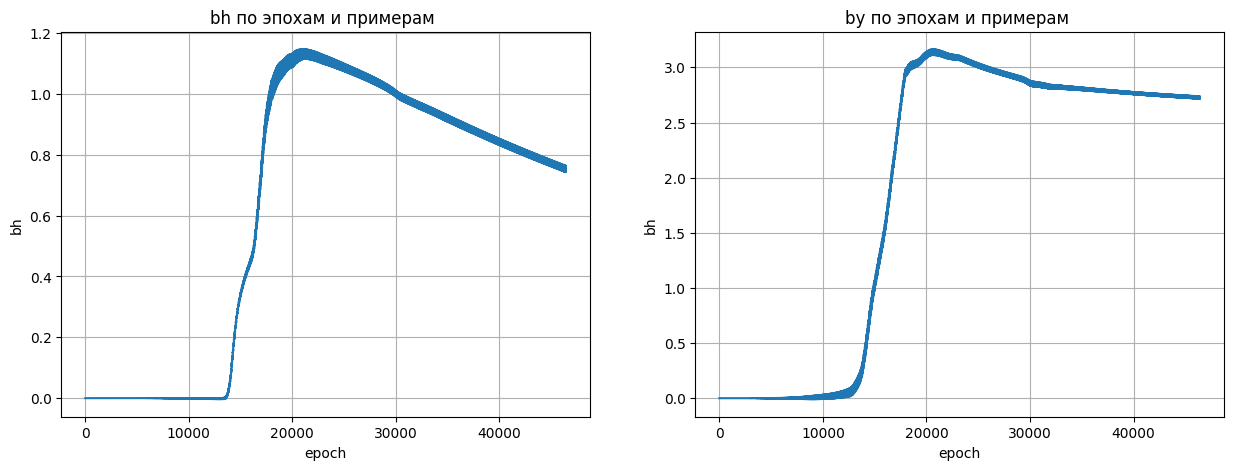

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title('bh по эпохам и примерам ')
plt.xlabel('epoch')
plt.ylabel('bh')
plt.grid()
plt.plot(W[:,1,0])
plt.subplot(1,2,2)
plt.plot(W[:,0,0])
plt.title('by по эпохам и примерам ')
plt.xlabel('epoch')
plt.ylabel('bh')
plt.grid()
plt.show()

/tmp/ipykernel_3158/143885489.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


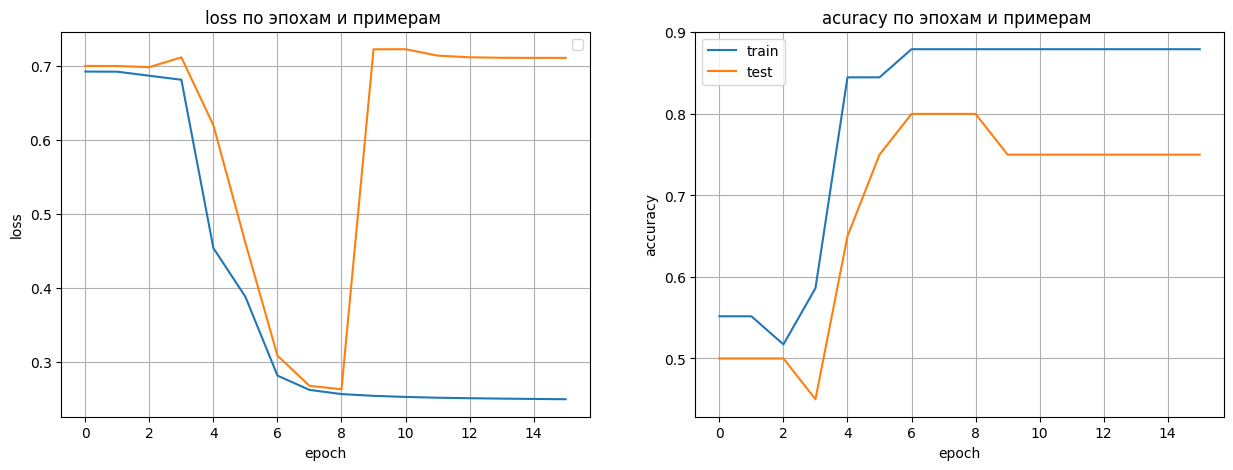

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title('loss по эпохам и примерам ')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid()
plt.plot(loss,label='train')
plt.plot(loss_test,label='test')
plt.subplot(1,2,2)
plt.plot(num_correct,label='train')

plt.plot(num_correct_test,label='test')
plt.title('acuracy по эпохам и примерам ')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.grid()
plt.show()

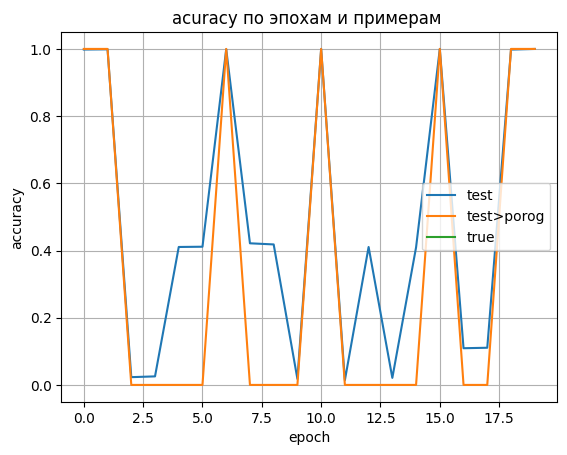

In [ ]:
y_pred = np.argmax(y_p, axis=1)
probs=np.array(y_p)
y_list = y
plt.plot(np.array(probs[:,1]), label='test')
plt.plot(np.array(y_pred),label='test>porog')
plt.plot(np.array(y_list),label='true')
plt.title('acuracy по эпохам и примерам ')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.grid()
plt.show()

## Задание 2. Исследование RNN для классификации фраз


**1.1.** Оцените зависимость качества классификации от числа скрытых нейронов (`hidden_size`).

**1.2.** Оцените изменение качества при разных значениях скорости обучения (`learn_rate`).

**1.3.** Замените исходное представление текста на векторизацию с помощью `CountVectorizer` и `TfidfVectorizer` из sklearn и оцените изменение качества.


### 1.4. Дополнительное исследование по варианту

Выполните один вариант в соответствии с номером в списке группы. Пункты 1.1–1.3 выполняют все.

**Вариант 1.** Сравните предсказания для пар фраз, различающихся отрицанием или порядком слов (например, `good / not good`). Проанализируйте, учитывает ли сеть контекст.

**Вариант 2.** У обученной модели обнулите `Whh` без переобучения. Сравните качество и предсказания на тех же тестовых фразах до и после отключения рекуррентной связи.

**Вариант 3.** Исследуйте влияние расстояния между отрицанием и значимым словом (например, `not good`, `not very good`, `not at all good`). Сравните классы и вероятности; добавьте положительные фразы для контроля.

Представьте результаты в таблице или на графике и сделайте вывод. Проверочные фразы не используйте для дообучения.

    

In [ ]:
def train_rnn_generic(inputs_dict, test_dict, input_builder, input_size,
                      hidden_size=3, learn_rate=2e-2, epochs=300, seed=42, log_every=None):
    np.random.seed(seed)
    Whh, Wxh, Why, by, bh = init(input_size=input_size, output_size=2, hidden_size=hidden_size)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(epochs):
        train_loss = 0.0
        train_acc = 0

        for x, y in inputs_dict.items():
            inp_x = input_builder(x)
            target = int(y)

            out, h, last_h = forward(inputs=inp_x, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
            probs = softmax(out)

            d_L_d_y = probs.copy()
            d_L_d_y[target] -= 1

            Whh, Wxh, Why, by, bh = backprop(
                last_inputs=inp_x, d_y=d_L_d_y, last_hs=last_h,
                learn_rate=learn_rate, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh
            )

            train_loss -= np.sum(np.log(probs[1]) * y + np.log(probs[0]) * (1 - y))
            train_acc += int(np.argmax(probs) == y)

        test_loss = 0.0
        test_acc = 0
        for x, y in test_dict.items():
            inp_x = input_builder(x)
            out, h, last_h = forward(inputs=inp_x, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
            probs = softmax(out)
            test_loss -= np.sum(np.log(probs[1]) * y + np.log(probs[0]) * (1 - y))
            test_acc += int(np.argmax(probs) == y)

        history['train_loss'].append(train_loss / len(inputs_dict))
        history['train_acc'].append(train_acc / len(inputs_dict))
        history['test_loss'].append(test_loss / len(test_dict))
        history['test_acc'].append(test_acc / len(test_dict))

        if log_every and (epoch + 1) % log_every == 0:
            print(f"epoch {epoch+1:4d} | train_loss={history['train_loss'][-1]:.4f} "
                  f"acc={history['train_acc'][-1]:.3f} | "
                  f"test_loss={history['test_loss'][-1]:.4f} acc={history['test_acc'][-1]:.3f}")

    model = (Whh, Wxh, Why, by, bh)
    return history, model


def onehot_builder(text):
    return createInputs(text)

hidden_size 1
epoch  100 | train_loss=0.6927 acc=0.552 | test_loss=0.7003 acc=0.500
epoch  200 | train_loss=0.6895 acc=0.552 | test_loss=0.6989 acc=0.500
epoch  300 | train_loss=0.6294 acc=0.724 | test_loss=0.6587 acc=0.750
epoch  400 | train_loss=0.4067 acc=0.862 | test_loss=0.9847 acc=0.550
epoch  500 | train_loss=0.3302 acc=0.879 | test_loss=0.8865 acc=0.600
hidden_size 2
epoch  100 | train_loss=0.6922 acc=0.552 | test_loss=0.7000 acc=0.500
epoch  200 | train_loss=0.6793 acc=0.586 | test_loss=0.7195 acc=0.450
epoch  300 | train_loss=0.0718 acc=1.000 | test_loss=0.0901 acc=1.000
epoch  400 | train_loss=0.0126 acc=1.000 | test_loss=0.0150 acc=1.000
epoch  500 | train_loss=0.0068 acc=1.000 | test_loss=0.0081 acc=1.000
hidden_size 3
epoch  100 | train_loss=0.6927 acc=0.552 | test_loss=0.7003 acc=0.500
epoch  200 | train_loss=0.6842 acc=0.552 | test_loss=0.7036 acc=0.500
epoch  300 | train_loss=0.3013 acc=0.879 | test_loss=0.4020 acc=0.750
epoch  400 | train_loss=0.0153 acc=1.000 | test_

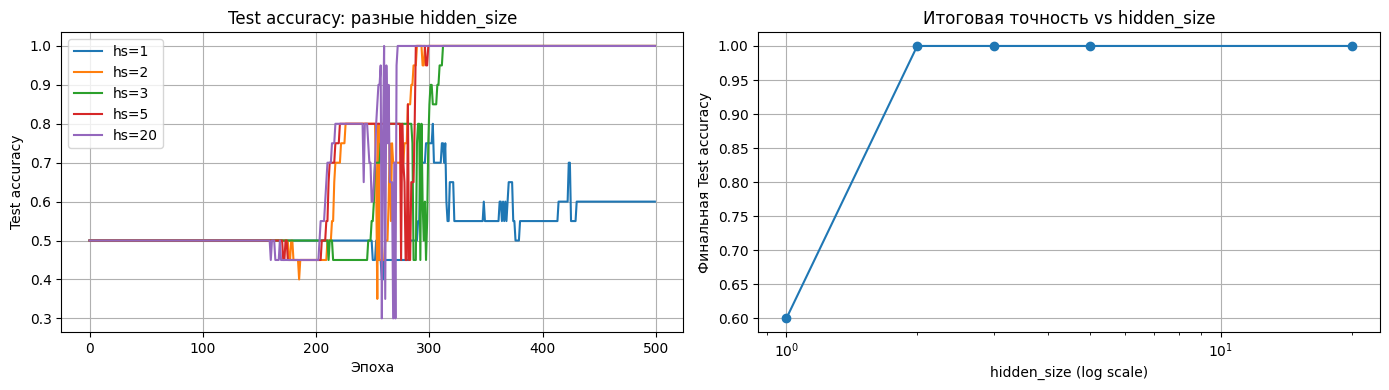

Итоговые Test accuracy:
  hidden_size= 1: 0.600
  hidden_size= 2: 1.000
  hidden_size= 3: 1.000
  hidden_size= 5: 1.000
  hidden_size=20: 1.000


In [ ]:
#2.1
hidden_sizes = [1, 2, 3, 5, 20]
results_hs = {}
final_test_acc = []

for hs in hidden_sizes:
    print(f"hidden_size {hs}")
    hist, model = train_rnn_generic(
        train_data, test_data, onehot_builder, input_size=len(vocab),
        hidden_size=hs, learn_rate=2e-2, epochs=500, seed=42, log_every=100
    )
    results_hs[hs] = hist
    final_test_acc.append(hist['test_acc'][-1])

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for hs in hidden_sizes:
    plt.plot(results_hs[hs]['test_acc'], label=f'hs={hs}')
plt.xlabel('Эпоха'); plt.ylabel('Test accuracy')
plt.title('Test accuracy: разные hidden_size')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(hidden_sizes, final_test_acc, 'o-')
plt.xscale('log')
plt.xlabel('hidden_size (log scale)'); plt.ylabel('Финальная Test accuracy')
plt.title('Итоговая точность vs hidden_size')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Итоговые Test accuracy:")
for hs, acc in zip(hidden_sizes, final_test_acc):
    print(f"  hidden_size={hs:>2}: {acc:.3f}")

При 1 скрытом недоучиваемся, а при 2 и более уже нормально, так что требуется несколько слоев

learn_rate 0.001
epoch  100 | train_loss=0.6880 acc=0.552 | test_loss=0.6980 acc=0.500
epoch  200 | train_loss=0.6880 acc=0.552 | test_loss=0.6986 acc=0.500
epoch  300 | train_loss=0.6880 acc=0.552 | test_loss=0.6986 acc=0.500
learn_rate 0.005
epoch  100 | train_loss=0.6890 acc=0.552 | test_loss=0.6989 acc=0.500
epoch  200 | train_loss=0.6890 acc=0.552 | test_loss=0.6989 acc=0.500
epoch  300 | train_loss=0.6890 acc=0.552 | test_loss=0.6989 acc=0.500
learn_rate 0.02
epoch  100 | train_loss=0.6927 acc=0.552 | test_loss=0.7003 acc=0.500
epoch  200 | train_loss=0.6842 acc=0.552 | test_loss=0.7036 acc=0.500
epoch  300 | train_loss=0.3013 acc=0.879 | test_loss=0.4020 acc=0.750
learn_rate 0.05
epoch  100 | train_loss=0.6954 acc=0.500 | test_loss=0.7012 acc=0.500
epoch  200 | train_loss=0.1113 acc=0.966 | test_loss=0.2276 acc=0.900
epoch  300 | train_loss=0.0042 acc=1.000 | test_loss=0.0049 acc=1.000
learn_rate 0.1
epoch  100 | train_loss=0.7110 acc=0.466 | test_loss=0.7009 acc=0.500
epoch  20

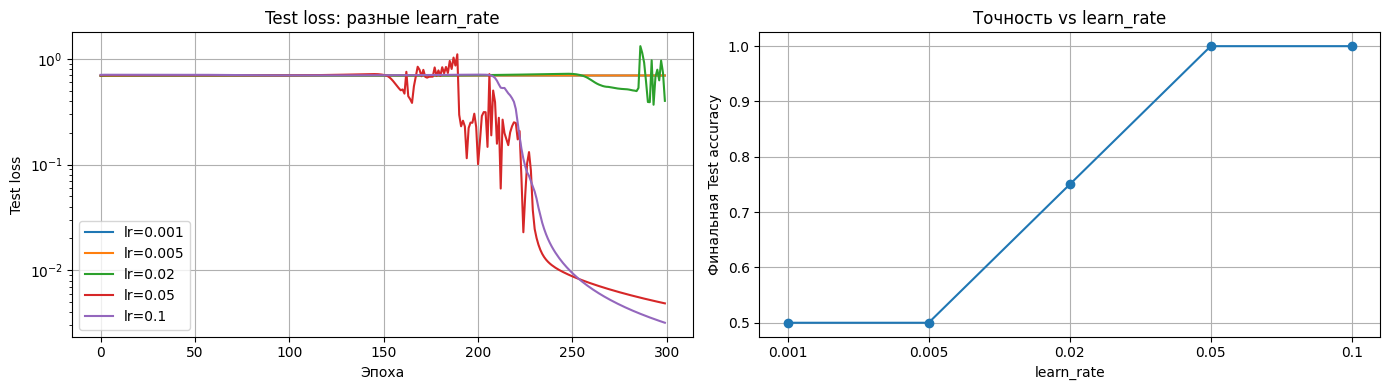

Итоговые Test accuracy:
  learn_rate=  0.001: 0.500
  learn_rate=  0.005: 0.500
  learn_rate=   0.02: 0.750
  learn_rate=   0.05: 1.000
  learn_rate=    0.1: 1.000


In [ ]:
#2.2
learn_rates = [1e-3, 5e-3, 2e-2, 5e-2, 1e-1]
results_lr = {}
final_lr_acc = []

for lr in learn_rates:
    print(f"learn_rate {lr}")
    hist, model = train_rnn_generic(
        train_data, test_data, onehot_builder, input_size=len(vocab),
        hidden_size=3, learn_rate=lr, epochs=300, seed=42, log_every=100
    )
    results_lr[lr] = hist
    final_lr_acc.append(hist['test_acc'][-1])

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for lr in learn_rates:
    plt.plot(results_lr[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха'); plt.ylabel('Test loss')
plt.yscale('log')
plt.title('Test loss: разные learn_rate')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot([str(lr) for lr in learn_rates], final_lr_acc, 'o-')
plt.xlabel('learn_rate'); plt.ylabel('Финальная Test accuracy')
plt.title('Точность vs learn_rate')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Итоговые Test accuracy:")
for lr, acc in zip(learn_rates, final_lr_acc):
    print(f"  learn_rate={lr:>7}: {acc:.3f}")

learn_rate нужен более 0.05, а иначе модель застревает в начальном плато и недоучивается, слишком медленно ползет.



CV vocab size:    17
TfIdf vocab size: 17
one-hot (базовая RNN)
epoch  150 | train_loss=0.6910 acc=0.552 | test_loss=0.6994 acc=0.500
epoch  300 | train_loss=0.3013 acc=0.879 | test_loss=0.4020 acc=0.750
CountVectorizer
epoch  150 | train_loss=0.0841 acc=0.983 | test_loss=0.1476 acc=0.950
epoch  300 | train_loss=0.0475 acc=0.983 | test_loss=0.1376 acc=0.950
TfidfVectorizer
epoch  150 | train_loss=0.5694 acc=0.793 | test_loss=0.6495 acc=0.750
epoch  300 | train_loss=0.1218 acc=0.983 | test_loss=0.1698 acc=0.950
Итоговая Test accuracy:
         one-hot (RNN): 0.750
       CountVectorizer: 0.950
       TfidfVectorizer: 0.950


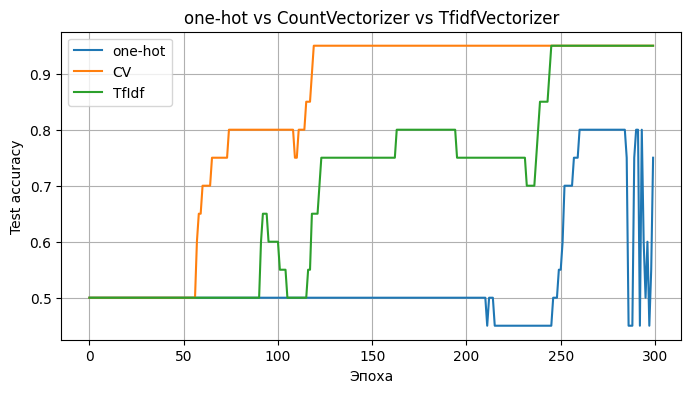

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

train_texts = list(train_data.keys())

cv = CountVectorizer().fit(train_texts)
tfidf = TfidfVectorizer().fit(train_texts)

def cv_builder(text):
    vec = cv.transform([text]).toarray()[0].reshape(-1, 1)
    return [vec]

def tfidf_builder(text):
    vec = tfidf.transform([text]).toarray()[0].reshape(-1, 1)
    return [vec]

print(f"CV vocab size:    {len(cv.vocabulary_)}")
print(f"TfIdf vocab size: {len(tfidf.vocabulary_)}")

print("one-hot (базовая RNN)")
hist_onehot, _ = train_rnn_generic(
    train_data, test_data, onehot_builder, input_size=len(vocab),
    hidden_size=3, learn_rate=2e-2, epochs=300, seed=42, log_every=150
)

print("CountVectorizer")
hist_cv, _ = train_rnn_generic(
    train_data, test_data, cv_builder, input_size=len(cv.vocabulary_),
    hidden_size=3, learn_rate=2e-2, epochs=300, seed=42, log_every=150
)

print("TfidfVectorizer")
hist_tfidf, _ = train_rnn_generic(
    train_data, test_data, tfidf_builder, input_size=len(tfidf.vocabulary_),
    hidden_size=3, learn_rate=2e-2, epochs=300, seed=42, log_every=150
)

summary = {
    'one-hot (RNN)':    hist_onehot['test_acc'][-1],
    'CountVectorizer':  hist_cv['test_acc'][-1],
    'TfidfVectorizer':  hist_tfidf['test_acc'][-1],
}
print("Итоговая Test accuracy:")
for k, v in summary.items():
    print(f"  {k:>20}: {v:.3f}")

plt.figure(figsize=(8, 4))
for name, hist in [('one-hot', hist_onehot), ('CV', hist_cv), ('TfIdf', hist_tfidf)]:
    plt.plot(hist['test_acc'], label=name)
plt.xlabel('Эпоха'); plt.ylabel('Test accuracy')
plt.title('one-hot vs CountVectorizer vs TfidfVectorizer')
plt.legend(); plt.grid(True)
plt.show()

CV  быстрее сходится, TfIdf  сходится, но с большим числом эпох, а вот one-hot обычный за 300 эпох не достиг их успехов

Обучение базовой RNN
epoch  200 | train_loss=0.6842 acc=0.552 | test_loss=0.7036 acc=0.500
epoch  400 | train_loss=0.0153 acc=1.000 | test_loss=0.0191 acc=1.000
epoch  600 | train_loss=0.0044 acc=1.000 | test_loss=0.0056 acc=1.000
Фраза                 Ожид.   P(pos)    Pred    OK?
good                  True    0.994     True    ok
happy                 True    0.993     True    ok
very good             True    0.997     True    ok
very happy            True    0.997     True    ok
very very good        True    0.998     True    ok
not good              False   0.003     False   ok
not happy             False   0.003     False   ok
not very good         False   0.002     False   ok
not very happy        False   0.002     False   ok
not very very very very very at all happyFalse   0.003     False   ok
not at all good       False   0.005     False   ok
not at all happy      False   0.005     False   ok
not not good          True    0.012     False   not ok
not very very very very very no

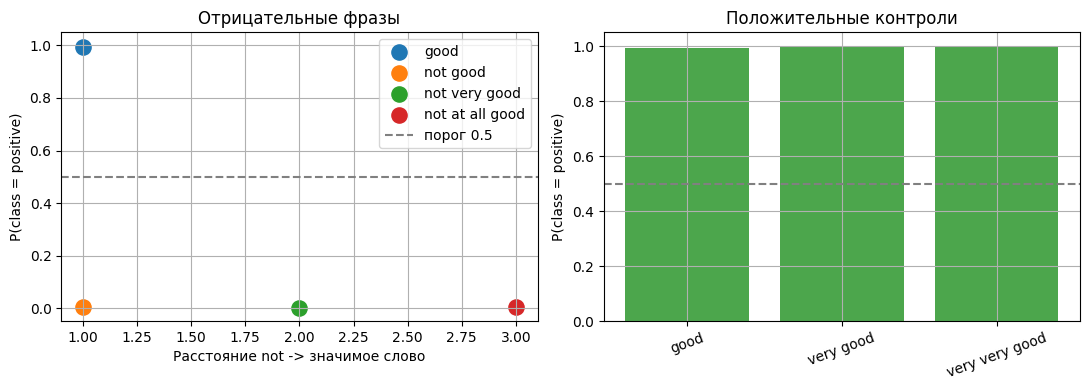


Средняя P(pos):
  положительные контроли  : 0.996
  not good (dist=1)       : 0.003
  not very good (dist=2)  : 0.002
  not at all good (dist=3): 0.005


In [ ]:
#var 3
print("Обучение базовой RNN")
hist_var3, model_var3 = train_rnn_generic(
    train_data, test_data, onehot_builder, input_size=len(vocab),
    hidden_size=3, learn_rate=2e-2, epochs=600, seed=42, log_every=200
)

def predict_positive_prob(model, text):
    Whh, Wxh, Why, by, bh = model
    inp_x = createInputs(text)
    out, h, last_h = forward(inputs=inp_x, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
    probs = softmax(out).flatten()
    return float(probs[1])

control_phrases = [
    # положительные контроли
    ("good",              True),
    ("happy",             True),
    ("very good",         True),
    ("very happy",        True),
    ("very very good",    True),
    # отрицания с разной дистанцией до значимого слова
    ("not good",          False),   # dist=1
    ("not happy",         False),
    ("not very good",     False),   # dist=2
    ("not very happy",    False),
    ("not very very very very very at all happy",    False), # dist=много
    ("not at all good",   False),   # dist=3
    ("not at all happy",  False),
    ("not not good",      True),    # двойное отрицание
    ("not very very very very very not very very very very good",      True),
]

print(f"{'Фраза':<22}{'Ожид.':<8}{'P(pos)':<10}{'Pred':<8}{'OK?'}")
rows = []
for phrase, expected in control_phrases:
    p = predict_positive_prob(model_var3, phrase)
    pred = p > 0.5
    ok = "ok" if pred == expected else "not ok"
    rows.append((phrase, expected, p, pred, ok))
    print(f"{phrase:<22}{str(expected):<8}{p:<10.3f}{str(pred):<8}{ok}")

neg_examples = [
    ("good",            1),
    ("not good",        1),
    ("not very good",   2),
    ("not at all good", 3),
]
pos_examples = [
    ("good",            0),
    ("very good",       0),
    ("very very good",  0),
]

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for phrase, dist in neg_examples:
    p = predict_positive_prob(model_var3, phrase)
    plt.scatter(dist, p, s=120, label=phrase)
plt.axhline(0.5, color='gray', linestyle='--', label='порог 0.5')
plt.xlabel('Расстояние not -> значимое слово')
plt.ylabel('P(class = positive)')
plt.title('Отрицательные фразы')
plt.ylim(-0.05, 1.05); plt.grid(True); plt.legend()

plt.subplot(1, 2, 2)
for phrase, _ in pos_examples:
    p = predict_positive_prob(model_var3, phrase)
    plt.bar(phrase, p, color='green', alpha=0.7)
plt.axhline(0.5, color='gray', linestyle='--')
plt.ylabel('P(class = positive)')
plt.title('Положительные контроли')
plt.ylim(0, 1.05); plt.grid(True); plt.xticks(rotation=20)

plt.tight_layout(); plt.show()

# 4) Числовая сводка по группам
def mean_p(phrases):
    return np.mean([predict_positive_prob(model_var3, p) for p, _ in phrases])

print("\nСредняя P(pos):")
print(f"  положительные контроли  : {mean_p([('good', True), ('very good', True), ('very very good', True)]):.3f}")
print(f"  not good (dist=1)       : {predict_positive_prob(model_var3, 'not good'):.3f}")
print(f"  not very good (dist=2)  : {predict_positive_prob(model_var3, 'not very good'):.3f}")
print(f"  not at all good (dist=3): {predict_positive_prob(model_var3, 'not at all good'):.3f}")

Разница между резульатами дистанций несущественна, а вот на двойном отрицании не вышло угадать, скорее из-за того, что этого не было в тренировочных

## Задание 3.

1. провести моделирование данных для задачи предсказания значения функции по n предидущим



Train: 295 примеров, shape входа: (1, 1)
Test : 295 примеров
x_train  [-0.91, 1.53]
x_test   [-0.39, 2.16]


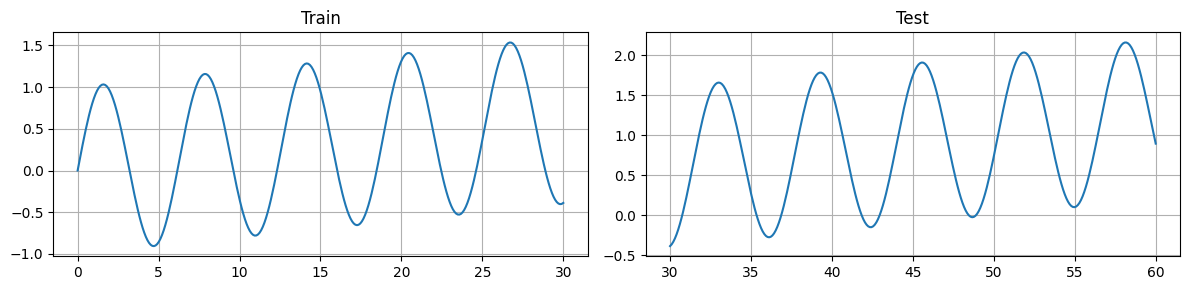

In [ ]:
def f_target(t):
    return np.sin(t) + 0.02 * t

def make_windows(t_arr, window=5, horizon=1):
    x = f_target(t_arr)
    X, Y, tt = [], [], []
    for i in range(len(t_arr) - window - horizon + 1):
        seq = [np.array([[x[i + j]]]) for j in range(window)]  # (1,1)
        X.append(seq)
        Y.append(x[i + window + horizon - 1])
        tt.append(t_arr[i + window + horizon - 1])
    return X, np.array(Y), np.array(tt)

N = 300
t_train = np.linspace(0, 30, N)
t_test  = np.linspace(30, 60, N)

X_train, y_train, tt_train = make_windows(t_train, window=5)
X_test,  y_test,  tt_test  = make_windows(t_test,  window=5)

print(f"Train: {len(X_train)} примеров, shape входа: {X_train[0][0].shape}")
print(f"Test : {len(X_test)} примеров")
print(f"x_train  [{f_target(t_train).min():.2f}, {f_target(t_train).max():.2f}]")
print(f"x_test   [{f_target(t_test).min():.2f}, {f_target(t_test).max():.2f}]")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(t_train, f_target(t_train)); ax[0].set_title('Train'); ax[0].grid()
ax[1].plot(t_test,  f_target(t_test));  ax[1].set_title('Test');  ax[1].grid()
plt.tight_layout(); plt.show()

In [ ]:
def train_regression(X, Y, input_size=1, hidden_size=5,
                     learn_rate=1e-2, epochs=200, seed=42):
    np.random.seed(seed)
    Whh, Wxh, Why, by, bh = init(input_size=input_size, output_size=1,
                                 hidden_size=hidden_size)
    for ep in range(epochs):
        L = 0.0
        for seq, y_val in zip(X, Y):
            out, h, lh = forward(inputs=seq, Whh=Whh, Wxh=Wxh,
                                 Why=Why, by=by, bh=bh)
            d_y = out - np.array([[y_val]])
            Whh, Wxh, Why, by, bh = backprop(
                last_inputs=seq, d_y=d_y, last_hs=lh,
                learn_rate=learn_rate,
                Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
            L += (out[0, 0] - y_val) ** 2
        if (ep + 1) % 50 == 0:
            print(f"  epoch {ep+1:3d}  MSE={L/len(X):.6f}")
    return (Whh, Wxh, Why, by, bh)

def predict(X, model):
    Whh, Wxh, Why, by, bh = model
    return np.array([
        forward(inputs=seq, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)[0][0, 0]
        for seq in X
    ])

model = train_regression(X_train, y_train,
                         hidden_size=5, learn_rate=1e-2, epochs=200)

pred_tr = predict(X_train, model)
pred_te = predict(X_test,  model)

mse_tr = np.mean((pred_tr - y_train) ** 2)
mse_te = np.mean((pred_te - y_test)  ** 2)
print(f"MSE train = {mse_tr:.6f}")
print(f"MSE test  = {mse_te:.6f}")

  epoch  50  MSE=0.003757
  epoch 100  MSE=0.002843
  epoch 150  MSE=0.002747
  epoch 200  MSE=0.002666
MSE train = 0.002825
MSE test  = 0.007774


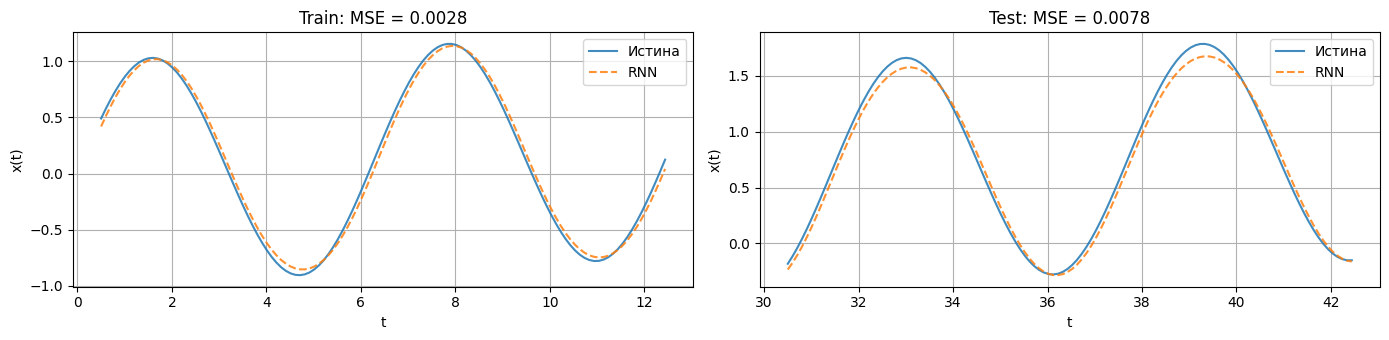

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))

ax[0].plot(tt_train[:120], y_train[:120], label='Истина', alpha=0.85)
ax[0].plot(tt_train[:120], pred_tr[:120], '--', label='RNN', alpha=0.85)
ax[0].set_title(f'Train: MSE = {mse_tr:.4f}')
ax[0].set_xlabel('t'); ax[0].set_ylabel('x(t)')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(tt_test[:120], y_test[:120], label='Истина', alpha=0.85)
ax[1].plot(tt_test[:120], pred_te[:120], '--', label='RNN', alpha=0.85)
ax[1].set_title(f'Test: MSE = {mse_te:.4f}')
ax[1].set_xlabel('t'); ax[1].set_ylabel('x(t)')
ax[1].legend(); ax[1].grid(True)

plt.tight_layout(); plt.show()

**Функция**

Text(0, 0.5, 'x')

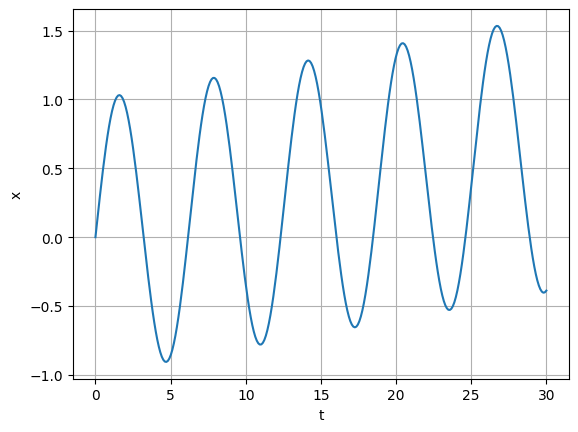

In [ ]:
N = 300
t = np.linspace(0,30,N).reshape((N,1))
x = np.sin(t) + t*0.02
plt.plot(t, x)
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

Пример 1: Сборка данных напрямую:

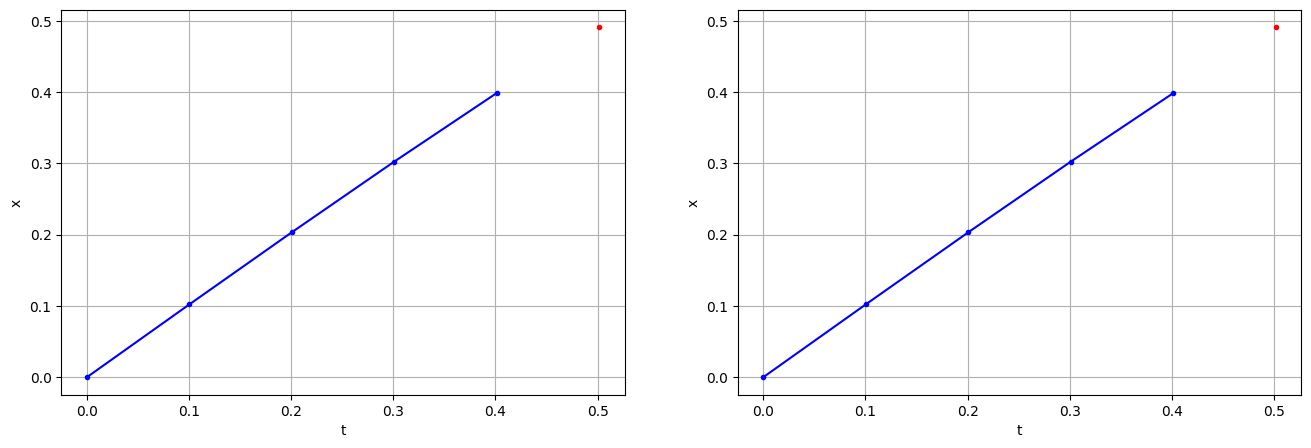

((5,), (294, 5, 2))

In [ ]:
N = 300
t = np.linspace(0,30,N).reshape((N,1))
x = np.sin(t) + t*0.02
n = 2 # длина вектора примера([t, x]) -  варьируемый параметр
xLen = 5 # длина последовательности -  варьируемый параметр



h = 1  # горизонт прогноза -  варьируемый параметр
# TRAIN
xx = []
y = []
inputs_ = []
for i in range(N-xLen - h):
    xx.append(np.concatenate( (t[i:xLen+i],x[i:xLen+i])).reshape((xLen,2)))
    y.append(x[i+h+xLen-1])
    x_in = [np.array([t[i+j][0],x[i+j][0]]) for j in range(xLen)]
    inputs_.append([x_in, x[i+h+xLen-1]])
xx = np.array(xx)
y = np.array(y)

plt.figure(figsize=(16, 5))
plt.subplot(1,2,1)
plt.plot(t[0:xLen],x[0:xLen],'.-b')
plt.plot(t[xLen+h-1],y[0],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.subplot(1,2,2)
x_y = inputs_[0]
tt = np.array(x_y[0])[:, 0]
y = np.array(x_y[0])[:, 1]
plt.plot(tt,y,'.-b')
plt.plot(tt[-1]+30/N,x_y[1],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.show()
y.shape,xx.shape

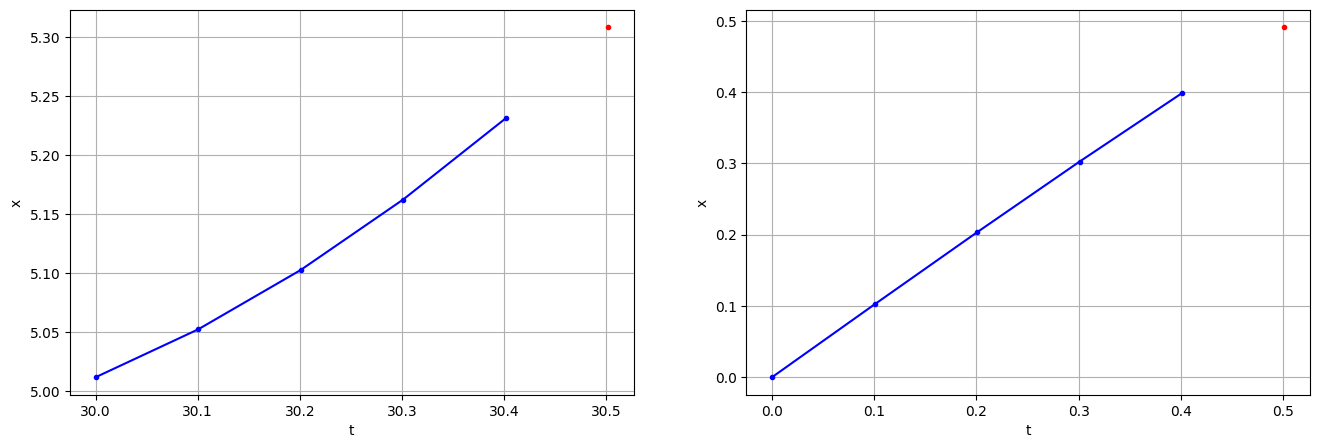

((5,), (294, 5, 2))

In [ ]:
## TEST
t = np.linspace(30,60,N).reshape((N,1))
x = np.sin(t) + t*0.2

xx = []
y = []
inputs_test = []
for i in range(N-xLen - h):
    xx.append(np.concatenate( (t[i:xLen+i],x[i:xLen+i])).reshape((xLen,2)))
    y.append(x[i+h+xLen-1])
    x_in = [np.array([t[i+j][0],x[i+j][0]]) for j in range(xLen-1)]
    inputs_test.append([x_in, x[i+h+xLen-1]])
xx = np.array(xx)
y = np.array(y)
plt.figure(figsize=(16, 5))
plt.subplot(1,2,1)
plt.plot(t[0:xLen],x[0:xLen],'.-b')
plt.plot(t[xLen+h-1],y[0],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.subplot(1,2,2)
x_y = inputs_[0]
tt = np.array(x_y[0])[:, 0]
y = np.array(x_y[0])[:, 1]
plt.plot(tt,y,'.-b')
plt.plot(tt[-1]+30/N,x_y[1],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.show()
y.shape,xx.shape

Пример 2: Разностная схема построения примера (на вход вектор разниц с последней известной точкой и сама эта точка):

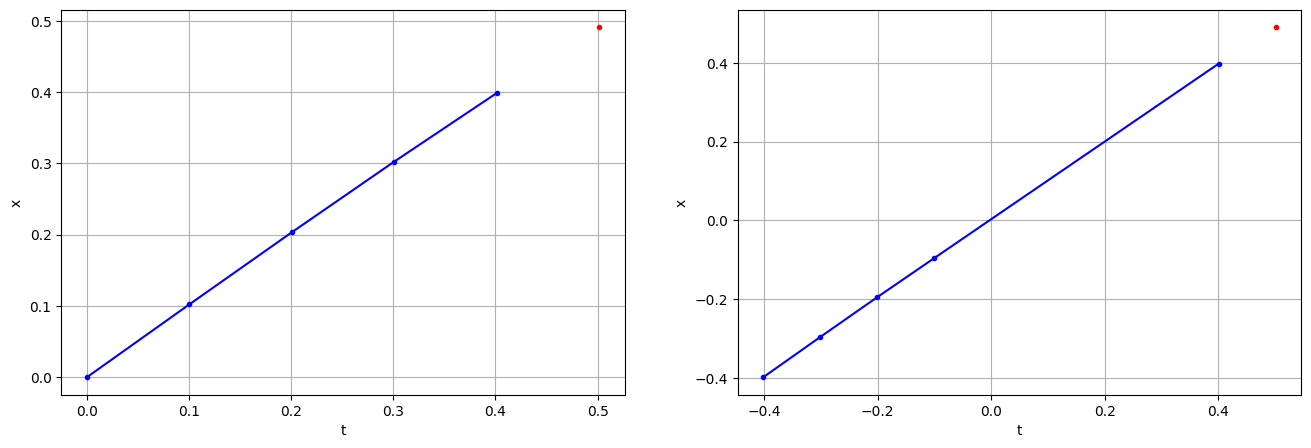

((5,), (294, 5, 2))

In [ ]:
N = 300
t = np.linspace(0,30,N).reshape((N,1))
x = np.sin(t) + t*0.02
n = 2 # длина вектора примера([t, x]) -  варьируемый параметр
xLen = 5 # длина последовательности -  варьируемый параметр



h = 1  # горизонт прогноза -  варьируемый параметр
# TRAIN
xx = []
y = []
inputs_ = []
for i in range(N-xLen - h):
    xx.append(np.concatenate( (t[i:xLen+i],x[i:xLen+i])).reshape((xLen,2)))
    y.append(x[i+h+xLen-1])
    x_in = [np.array([t[i+j][0]-t[i+ xLen-1][0],x[i+j][0]-x[i + xLen-1][0]]) for j in range(xLen-1)] + [np.array([t[i+xLen-1][0],x[i+xLen-1][0]])]
    inputs_.append([x_in, x[i+h+xLen-1]])
xx = np.array(xx)
y = np.array(y)

plt.figure(figsize=(16, 5))
plt.subplot(1,2,1)
plt.plot(t[0:xLen],x[0:xLen],'.-b')
plt.plot(t[xLen+h-1],y[0],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.subplot(1,2,2)
x_y = inputs_[0]
tt = np.array(x_y[0])[:, 0]
y = np.array(x_y[0])[:, 1]
plt.plot(tt,y,'.-b')
plt.plot(tt[-1]+30/N,x_y[1],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.show()
y.shape,xx.shape

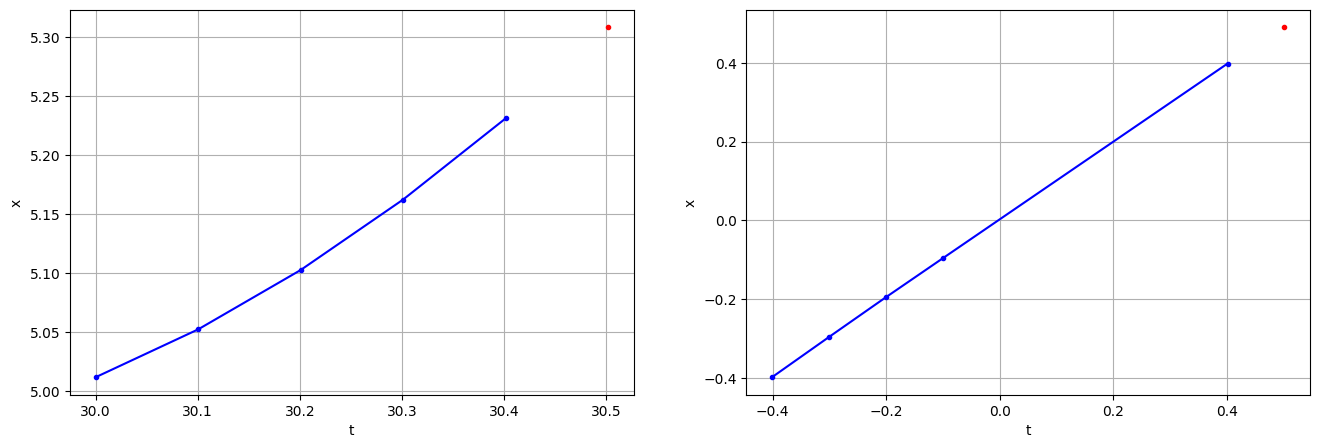

((5,), (294, 5, 2))

In [ ]:

t = np.linspace(30,60,N).reshape((N,1))
x = np.sin(t) + t*0.2

xx = []
y = []
inputs_test = []
for i in range(N-xLen - h):
    xx.append(np.concatenate( (t[i:xLen+i],x[i:xLen+i])).reshape((xLen,2)))
    y.append(x[i+h+xLen-1])
    x_in = [np.array([t[i+j][0]-t[i+ xLen-1][0],x[i+j][0]-x[i + xLen-1][0]]) for j in range(xLen-1)] + [np.array([t[i+xLen-1][0],x[i+xLen-1][0]])]
    inputs_test.append([x_in, x[i+h+xLen-1]])
xx = np.array(xx)
y = np.array(y)
plt.figure(figsize=(16, 5))
plt.subplot(1,2,1)
plt.plot(t[0:xLen],x[0:xLen],'.-b')
plt.plot(t[xLen+h-1],y[0],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.subplot(1,2,2)
x_y = inputs_[0]
tt = np.array(x_y[0])[:, 0]
y = np.array(x_y[0])[:, 1]
plt.plot(tt,y,'.-b')
plt.plot(tt[-1]+30/N,x_y[1],'.r')
plt.grid()
plt.xlabel('t')
plt.ylabel('x')

plt.show()
y.shape,xx.shape

In [ ]:
len(inputs_), len(inputs_test)

(294, 294)

In [ ]:
# переходим к запуску всего процесса целиком

# начальные ошибки и точность
loss = []
num_correct = []
loss_test = []
num_correct_test = []

print()
target_=[]
W=[]

# Цикл для каждого примера тренировки по всем эпохам
whh, wxh, why, by, bh =init(input_size=2, output_size=1, hidden_size=1)
last_hs=np.zeros(bh.shape)

# по эпохам
for epoch in range(8000):
        train_loss=0
        train_acc =0
        last_hs={}
        #print('epoch=',epoch)
        # по примерам
        for x_y in inputs_:
                # print(x_y)
                # строим пример
                inp_x = x_y[0]
                y = x_y[1]
                target = float(y[0]) # строим целевой вектор 0\1

                #ПРЯМОЙ ПРОХОД
                out, h, last_h=forward(inputs=inp_x,Whh=whh,Wxh=wxh,Why=why,by=by,bh=bh)
                #вычислим результат
                # print(out)
                probs = out
                # print(probs)
                #
                # Считаем производную по потерям dL/dy
                # 2 выхода probs-1 для того, что должно было быть и probs для второго варианта
                # т.е. если y=True, то  d_L_d_y[1]=probs-1, d_L_d_y[target]
                d_L_d_y = probs.copy()
                d_L_d_y -= y
                #print(d_L_d_y)
                # Обратное распространение
                whh,wxh,why,by, bh = backprop(last_inputs=inp_x,d_y=d_L_d_y,last_hs=last_h, learn_rate=2e-5,Whh=whh,Wxh=wxh,Why=why, by=by,bh=bh)
                #print([whh[0,0],wxh[0,0],why[0,0],by[0], bh[0]])
                #print(out,probs,y,np.sum(np.log(probs[1])*y+np.log(probs[0])*(1-y)))
                train_loss += (probs[0] - y)**2
                train_acc += (probs[0] - y)**2
                W.append(bh.copy())
        if (epoch % 500) == 499:
            print("длина последовательности на входе: ", len(inp_x), ", длина вектора в последовательности: ", len(inp_x[0]))
            test_loss = 0
            test_acc = 0
            y_p = []
            y_t = []
            for x_y in inputs_test:
                inp_x = x_y[0]
                y = x_y[1]
                target = int(y) # строим целевой вектор 0\1
                #print((whh))

                out, h, last_h=forward(inputs=inp_x, Whh=whh, Wxh=wxh, Why=why,by=by, bh=bh)
                #print('ghhgghhg:  ',x,y,': --- ',h.shape)
                probs =out
                y_p.append(probs[:,0].tolist())
                test_loss += (probs[0] - y)**2
                test_acc += (probs[0] - y)**2
                y_t.append(y)

            print('Эпоха %d' % (epoch + 1))
            print('Train:\tошибка %.3f | mse: %.3f' % (train_loss/len(train_data.items()), train_acc/len(train_data.items())))
            print('Test:\tошибка %.3f | mse: %.3f' % (test_loss/len(test_data.items()), test_acc/len(test_data.items())))
            loss.append(train_loss/len(train_data.items()))
            num_correct.append(train_acc/len(train_data.items()))
            loss_test.append(test_loss/len(test_data.items()))
            num_correct_test.append(test_acc/len(test_data.items()))
W=np.array(W)
loss_test=np.array(loss_test)
num_correct_test=np.array(num_correct_test)
loss=np.array(loss)
num_correct=np.array(num_correct)


длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 500
Train:	ошибка 2.555 | mse: 2.555
Test:	ошибка 1164.875 | mse: 1164.875


/tmp/ipykernel_3158/1454191003.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  target = int(y) # строим целевой вектор 0\1
/tmp/ipykernel_3158/1454191003.py:72: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('Train:\tошибка %.3f | mse: %.3f' % (train_loss/len(train_data.items()), train_acc/len(train_data.items())))
/tmp/ipykernel_3158/1454191003.py:73: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('Test:\tошибка %.3f | mse: %.3f' % (test_loss/len(te

длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 1000
Train:	ошибка 1.992 | mse: 1.992
Test:	ошибка 1090.937 | mse: 1090.937
длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 1500
Train:	ошибка 0.554 | mse: 0.554
Test:	ошибка 968.100 | mse: 968.100
длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 2000
Train:	ошибка 0.159 | mse: 0.159
Test:	ошибка 928.384 | mse: 928.384
длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 2500
Train:	ошибка 0.082 | mse: 0.082
Test:	ошибка 927.646 | mse: 927.646
длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 3000
Train:	ошибка 0.062 | mse: 0.062
Test:	ошибка 929.590 | mse: 929.590
длина последовательности на входе:  5 , длина вектора в последовательности:  2
Эпоха 3500
Train:	ошибка 0.059 | mse: 0.059
Test:	ошибка 927.660 | mse: 927.660
длина последовательности на входе:  5 , длин

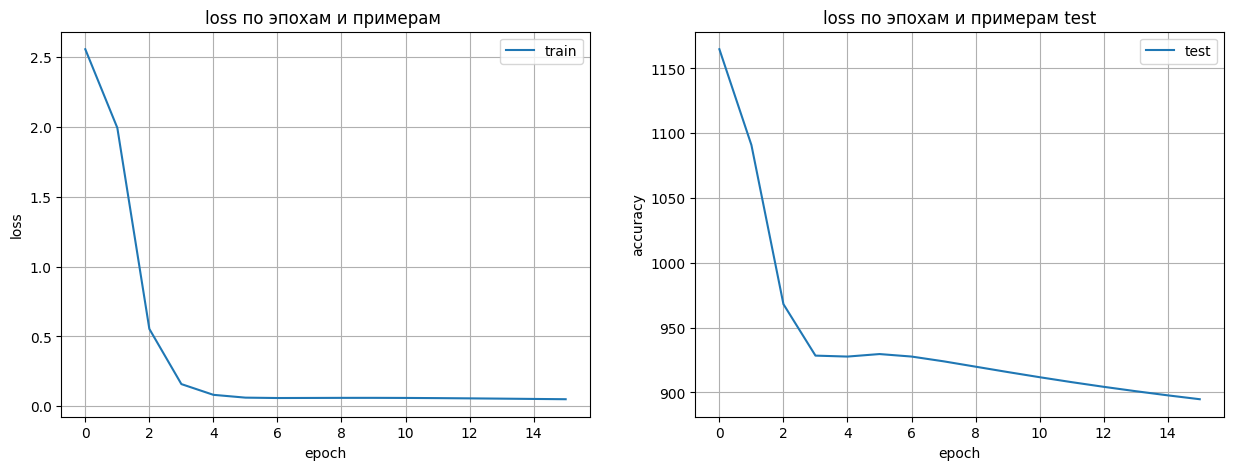

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title('loss по эпохам и примерам ')
plt.plot(loss,label='train')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid()


plt.subplot(1,2,2)
plt.plot(loss_test,label='test')
plt.title('loss по эпохам и примерам test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.grid()
plt.show()

# Домашнее задание. Прогнозирование значений функции с помощью RNN

Для функции своего варианта обучите рекуррентную нейронную сеть предсказывать будущее значение по последовательности предыдущих наблюдений. Исследуйте, как настройки модели и условия прогнозирования влияют на качество её ответов.

## Общая часть

1. Выберите функцию из списка вариантов и подготовьте обучающие и тестовые данные. Для каждого примера сформируйте входное окно из n предыдущих наблюдений и соответствующее будущее значение, которое должна предсказать сеть.
2. Обучите RNN и оцените качество прогноза на тестовых данных с помощью MSE. Покажите предсказанные и истинные значения на одном графике.
3. Исследуйте зависимость MSE от числа скрытых нейронов и длины входной последовательности. Меняйте один параметр за раз, представьте результаты в таблице или на графиках и объясните наблюдаемые различия.

## Исследование по варианту

Дополнительно выполните одно из следующих исследований в соответствии с номером в списке группы. Используйте ту же функцию, что и в общей части.

**Вариант 1. Сравнение с простым прогнозом.** Сравните RNN с правилом «следующее значение равно последнему известному». Рассчитайте MSE обоих способов на одинаковых тестовых точках и объясните, даёт ли нейросеть преимущество.

**Вариант 2. Влияние горизонта прогноза.** При фиксированной длине входного окна обучите отдельные модели для предсказания на 1, 3 и 5 шагов вперёд. Сравните MSE на общем наборе целевых времён и объясните, как изменение горизонта повлияло на качество.

**Вариант 3. Прогноз по собственным предсказаниям.** Выполните прогноз на 5 последовательных шагов: после каждого шага добавляйте предсказанное значение во входное окно вместо реального. Сравните ошибки с режимом, в котором перед очередным прогнозом доступно реальное наблюдение, используя одинаковые начальные окна и целевые точки.

Представьте результаты выбранного исследования в таблице или на графике и сформулируйте вывод.

## Дополнительное задание со звёздочкой

Используйте генетический алгоритм для подбора настроек модели, например числа скрытых нейронов и длины входной последовательности. Для реализации можно выбрать [DEAP](https://github.com/DEAP/deap), [PyGAD](https://pygad.readthedocs.io/en/latest/) или другой удобный пакет. Опишите, какие настройки подбирались, и сравните найденную конфигурацию с исходной. Для подбора используйте валидационные данные, а тестовые оставьте для итоговой оценки.

## Варианты функций
        
    
    
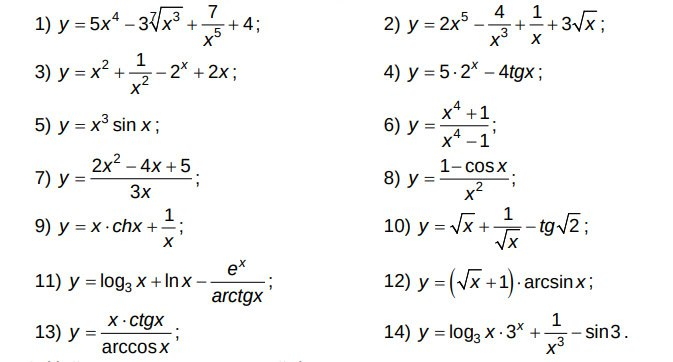
        
    

f(x) range:     [1.053, 5.309]
log f(x) range: [0.051, 1.669]
scaled range:   [-1.000, 1.000]


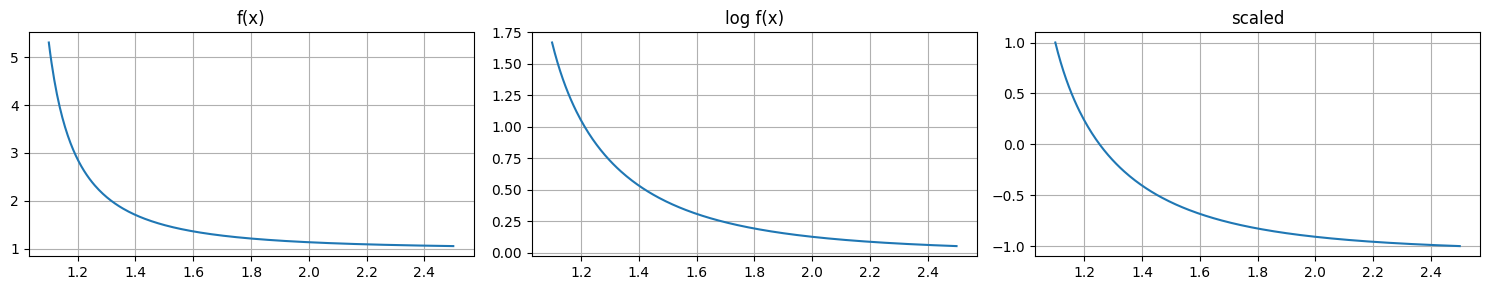

In [ ]:
def f_target(x):
    return (x**4 + 1) / (x**4 - 1)

def decode(scaled_val):
    log_val = (scaled_val + 1) / 2 * (log_y_max - log_y_min) + log_y_min
    log_val = np.clip(log_val, log_y_min - 0.5, log_y_max + 0.5)
    return np.exp(log_val)

# Данные
N = 300
x_all = np.linspace(1.1, 2.5, N)
y_all = f_target(x_all)

# Логарифм + min-max в [-1, 1]
log_y = np.log(y_all)
log_y_min, log_y_max = log_y.min(), log_y.max()
y_scaled = 2 * (log_y - log_y_min) / (log_y_max - log_y_min) - 1

print(f"f(x) range:     [{y_all.min():.3f}, {y_all.max():.3f}]")
print(f"log f(x) range: [{log_y_min:.3f}, {log_y_max:.3f}]")
print(f"scaled range:   [{y_scaled.min():.3f}, {y_scaled.max():.3f}]")

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
ax[0].plot(x_all, y_all); ax[0].set_title('f(x)'); ax[0].grid()
ax[1].plot(x_all, log_y); ax[1].set_title('log f(x)'); ax[1].grid()
ax[2].plot(x_all, y_scaled); ax[2].set_title('scaled'); ax[2].grid()
plt.tight_layout(); plt.show()

In [ ]:
def make_windows(y_scaled, window=5, horizon=1):
    X, Y = [], []
    for i in range(len(y_scaled) - window - horizon + 1):
        seq = [np.array([[y_scaled[i + j]]]) for j in range(window)]
        X.append(seq)
        Y.append(y_scaled[i + window + horizon - 1])
    return X, np.array(Y)

window_main = 5
X_all, Y_all = make_windows(y_scaled, window=window_main)
print(f"Окон: {len(X_all)}, форма входа одного окна: {X_all[0][0].shape}")

# Случайный split
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_all))
split = int(0.7 * len(X_all))
train_idx, test_idx = perm[:split], perm[split:]

X_train = [X_all[i] for i in train_idx]
Y_train = Y_all[train_idx]
X_test  = [X_all[i] for i in test_idx]
Y_test  = Y_all[test_idx]

print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Окон: 295, форма входа одного окна: (1, 1)
Train: 206, Test: 89


In [ ]:
def init_custom(input_size=1, output_size=1, hidden_size=5, seed=42):
    np.random.seed(seed)
    Whh = np.random.randn(hidden_size, hidden_size) * 0.1
    Wxh = np.random.randn(hidden_size, input_size) * 0.1
    Why = np.random.randn(output_size, hidden_size) * 0.1
    return Whh, Wxh, Why, np.zeros((output_size, 1)), np.zeros((hidden_size, 1))

def train_regression(X, Y, hidden_size=5, learn_rate=1e-2, epochs=300,
                     seed=42, verbose_every=None):
    np.random.seed(seed)
    Whh, Wxh, Why, by, bh = init_custom(hidden_size=hidden_size)
    losses = []
    for ep in range(epochs):
        L = 0.0
        for seq, y_val in zip(X, Y):
            out, h, lh = forward(inputs=seq, Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
            d_y = out - np.array([[y_val]])
            Whh, Wxh, Why, by, bh = backprop(
                last_inputs=seq, d_y=d_y, last_hs=lh, learn_rate=learn_rate,
                Whh=Whh, Wxh=Wxh, Why=Why, by=by, bh=bh)
            L += (out[0, 0] - y_val) ** 2
        losses.append(L / len(X))
        if verbose_every and (ep + 1) % verbose_every == 0:
            print(f"  epoch {ep+1:3d}  MSE_scaled={losses[-1]:.6f}")
    return (Whh, Wxh, Why, by, bh), losses

def predict(X, model):
    Whh, Wxh, Why, by, bh = model
    return np.array([forward(inputs=seq, Whh=Whh, Wxh=Wxh,
                             Why=Why, by=by, bh=bh)[0][0, 0] for seq in X])

In [ ]:
model_main, losses_main = train_regression(
    X_train, Y_train, hidden_size=5, learn_rate=1e-2,
    epochs=300, seed=42, verbose_every=50)

pred_tr_real = np.array([decode(p) for p in predict(X_train, model_main)])
pred_te_real = np.array([decode(p) for p in predict(X_test,  model_main)])
Y_train_real = np.array([decode(y) for y in Y_train])
Y_test_real  = np.array([decode(y) for y in Y_test])

mse_tr = np.mean((pred_tr_real - Y_train_real) ** 2)
mse_te = np.mean((pred_te_real - Y_test_real) ** 2)
print(f"\nMSE train = {mse_tr:.6f}")
print(f"MSE test  = {mse_te:.6f}")

  epoch  50  MSE_scaled=0.000297
  epoch 100  MSE_scaled=0.000209
  epoch 150  MSE_scaled=0.000163
  epoch 200  MSE_scaled=0.000134
  epoch 250  MSE_scaled=0.000115
  epoch 300  MSE_scaled=0.000100

MSE train = 0.000464
MSE test  = 0.000560


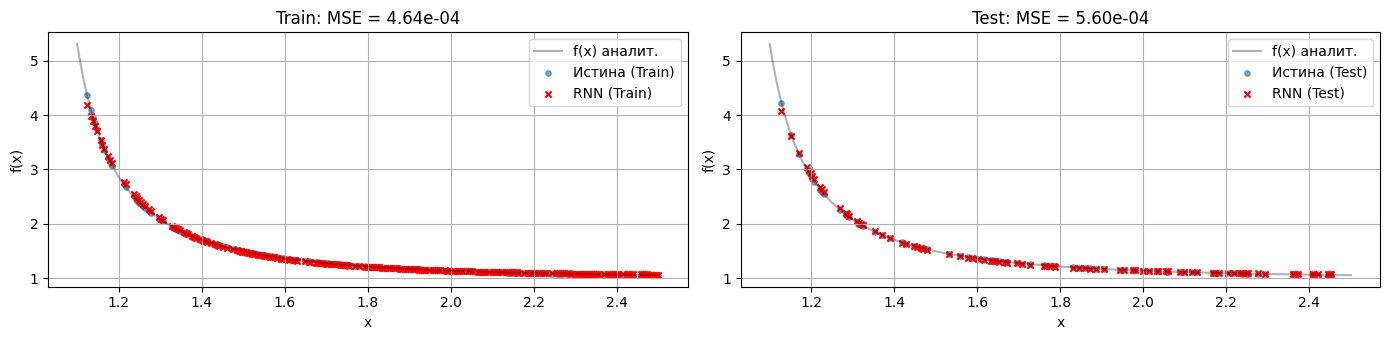

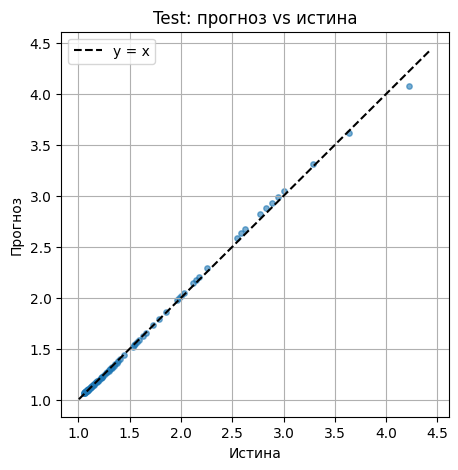

In [ ]:
x_targets = x_all[window_main:]   # x для каждого окна (после сдвига на window)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))

xf = np.linspace(1.1, 2.5, 500)
for a, idx, pred, y_true, label in [
    (ax[0], train_idx, pred_tr_real, Y_train_real, 'Train'),
    (ax[1], test_idx,  pred_te_real, Y_test_real,  'Test'),
]:
    a.plot(xf, f_target(xf), 'k-', alpha=0.3, label='f(x) аналит.')
    a.scatter(x_targets[idx], y_true, c='steelblue', s=15,
              alpha=0.7, label=f'Истина ({label})')
    a.scatter(x_targets[idx], pred, c='red', marker='x', s=20,
              label=f'RNN ({label})')
    a.set_xlabel('x'); a.set_ylabel('f(x)')
    a.legend(); a.grid(True)
ax[0].set_title(f'Train: MSE = {mse_tr:.2e}')
ax[1].set_title(f'Test: MSE = {mse_te:.2e}')
plt.tight_layout(); plt.show()

# Scatter y_pred vs y_true — компактная визуальная оценка
plt.figure(figsize=(5, 5))
plt.scatter(Y_test_real, pred_te_real, alpha=0.6, s=15)
lim = [min(Y_test_real.min(), pred_te_real.min()) * 0.95,
       max(Y_test_real.max(), pred_te_real.max()) * 1.05]
plt.plot(lim, lim, 'k--', label='y = x')
plt.xlabel('Истина'); plt.ylabel('Прогноз')
plt.title('Test: прогноз vs истина')
plt.legend(); plt.grid(True); plt.show()

### Задача 3. MSE от `hidden_size` и длины окна

Меняем один параметр за раз, но показываем сразу двумерную карту:
на этой функции хорошо видно, что **широкое окно само по себе не помогает** —
нужно и `hidden_size`, и `window` одновременно.

  hs= 3, win= 5: MSE_train=1.01e-03, MSE_test=1.21e-03
  hs= 3, win=10: MSE_train=4.47e-04, MSE_test=5.51e-04
  hs= 3, win=15: MSE_train=2.04e-04, MSE_test=2.75e-04
  hs= 5, win= 5: MSE_train=9.77e-04, MSE_test=1.15e-03
  hs= 5, win=10: MSE_train=4.99e-04, MSE_test=5.72e-04
  hs= 5, win=15: MSE_train=2.47e-04, MSE_test=3.02e-04
  hs=10, win= 5: MSE_train=3.86e-04, MSE_test=5.07e-04
  hs=10, win=10: MSE_train=1.66e-04, MSE_test=2.34e-04
  hs=10, win=15: MSE_train=1.03e-04, MSE_test=1.43e-04


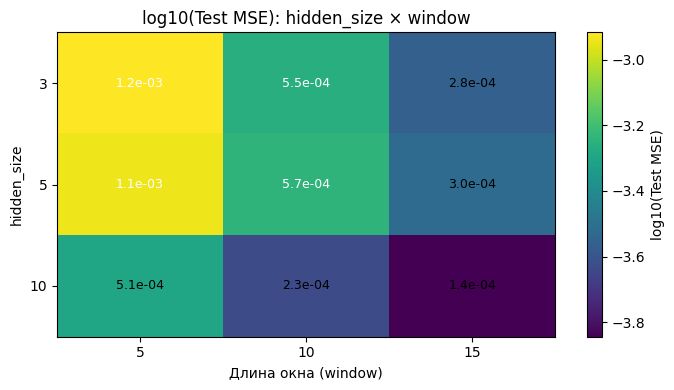


Лучшая: hidden=10, window=15, MSE_test=1.43e-04


In [ ]:
hidden_list = [3, 5, 10]
window_list = [5, 10, 15]

mse_grid = np.zeros((len(hidden_list), len(window_list)))
mse_tr_grid = np.zeros_like(mse_grid)

for hi, h in enumerate(hidden_list):
    for wi, w in enumerate(window_list):
        Xw, Yw = make_windows(y_scaled, window=w)
        rng_w = np.random.default_rng(42)
        perm_w = rng_w.permutation(len(Xw))
        sp = int(0.7 * len(Xw))
        X_tr_w = [Xw[i] for i in perm_w[:sp]]
        Y_tr_w = Yw[perm_w[:sp]]
        X_te_w = [Xw[i] for i in perm_w[sp:]]
        Y_te_w = Yw[perm_w[sp:]]

        m, _ = train_regression(X_tr_w, Y_tr_w, hidden_size=h,
                                learn_rate=1e-2, epochs=100, seed=42)
        p_tr = np.array([decode(p) for p in predict(X_tr_w, m)])
        p_te = np.array([decode(p) for p in predict(X_te_w, m)])
        y_tr_r = np.array([decode(v) for v in Y_tr_w])
        y_te_r = np.array([decode(v) for v in Y_te_w])

        mse_tr_grid[hi, wi] = np.mean((p_tr - y_tr_r) ** 2)
        mse_grid[hi, wi]    = np.mean((p_te - y_te_r) ** 2)
        print(f"  hs={h:>2}, win={w:>2}: MSE_train={mse_tr_grid[hi,wi]:.2e}, "
              f"MSE_test={mse_grid[hi,wi]:.2e}")

plt.figure(figsize=(7, 4))
plt.imshow(np.log10(mse_grid + 1e-10), cmap='viridis', aspect='auto')
plt.colorbar(label='log10(Test MSE)')
plt.xticks(range(len(window_list)), window_list)
plt.yticks(range(len(hidden_list)), hidden_list)
plt.xlabel('Длина окна (window)'); plt.ylabel('hidden_size')
plt.title('log10(Test MSE): hidden_size × window')
for i in range(len(hidden_list)):
    for j in range(len(window_list)):
        plt.text(j, i, f'{mse_grid[i,j]:.1e}', ha='center', va='center',
                 color='white' if mse_grid[i,j] > np.median(mse_grid) else 'black',
                 fontsize=9)
plt.tight_layout(); plt.show()

best = np.unravel_index(np.argmin(mse_grid), mse_grid.shape)
print(f"\nЛучшая: hidden={hidden_list[best[0]]}, window={window_list[best[1]]}, "
      f"MSE_test={mse_grid[best]:.2e}")

Лучшая конфигурация по сетке — hidden = 10, window = 15. Длина окна оказалась важнее числа размера скрытого слоя. При чем лучше увеличивать именно длину окна, так как при фиксации размера слоя при изменении длины окна будет лосс сильнее снижаться, чем если сделать наоборот

Autoregressive:  mean MSE = 1.94e-03
Oracle:          mean MSE = 4.14e-04
Отношение:       4.69x

Шаг  Истина      Auto        Oracle      
------------------------------------------
1    1.1188      1.1215      1.1215      
2    1.1176      1.1220      1.1204      
3    1.1165      1.1226      1.1194      
4    1.1154      1.1231      1.1184      
5    1.1143      1.1236      1.1174      


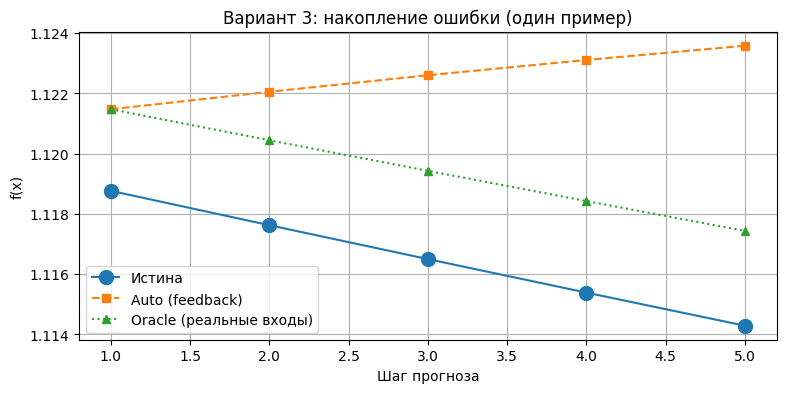

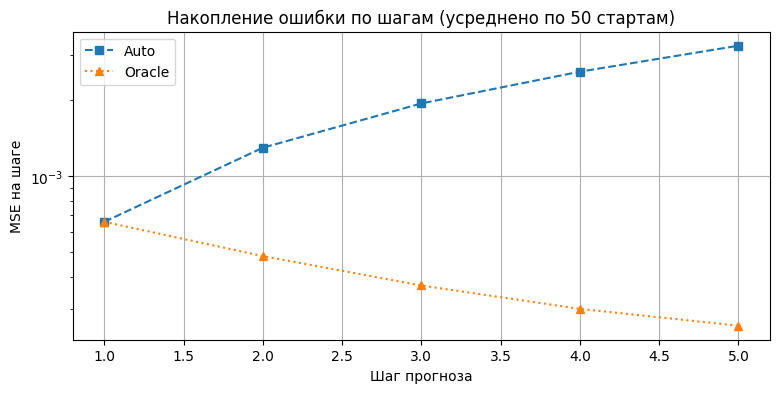

In [ ]:
valid_starts = [i for i in test_idx if i + 5 <= len(X_all)][:50]

auto_mse_per_start = []
oracle_mse_per_start = []
last_curves = None  # для визуализации одного примера

for s_i in valid_starts:
    init_w = [w.copy() for w in X_all[s_i]]
    targets_real = np.array([decode(Y_all[s_i + k]) for k in range(5)])

    cur_w = [w.copy() for w in init_w]
    pred_auto_scaled = []
    for _ in range(5):
        p = predict([cur_w], model_main)[0]
        pred_auto_scaled.append(p)
        cur_w = cur_w[1:] + [np.array([[p]])]
    pred_auto_real = np.array([decode(p) for p in pred_auto_scaled])

    real_windows = [X_all[s_i + k] for k in range(5)]
    pred_oracle_real = np.array([decode(p) for p in predict(real_windows, model_main)])

    auto_mse_per_start.append(np.mean((pred_auto_real   - targets_real) ** 2))
    oracle_mse_per_start.append(np.mean((pred_oracle_real - targets_real) ** 2))

    if last_curves is None:
        last_curves = (targets_real, pred_auto_real, pred_oracle_real)

print(f"Autoregressive:  mean MSE = {np.mean(auto_mse_per_start):.2e}")
print(f"Oracle:          mean MSE = {np.mean(oracle_mse_per_start):.2e}")
print(f"Отношение:       {np.mean(auto_mse_per_start) / np.mean(oracle_mse_per_start):.2f}x")

# Детализация по одному примеру
targets_real, pred_auto_real, pred_oracle_real = last_curves
print(f"\n{'Шаг':<5}{'Истина':<12}{'Auto':<12}{'Oracle':<12}")
print("-" * 42)
for k in range(5):
    print(f"{k+1:<5}{targets_real[k]:<12.4f}{pred_auto_real[k]:<12.4f}{pred_oracle_real[k]:<12.4f}")

plt.figure(figsize=(9, 4))
steps = np.arange(1, 6)
plt.plot(steps, targets_real, 'o-', markersize=10, label='Истина')
plt.plot(steps, pred_auto_real, 's--', label='Auto (feedback)')
plt.plot(steps, pred_oracle_real, '^:', label='Oracle (реальные входы)')
plt.xlabel('Шаг прогноза'); plt.ylabel('f(x)')
plt.title('Вариант 3: накопление ошибки (один пример)')
plt.legend(); plt.grid(True); plt.show()

err_auto_by_step = np.zeros(5)
err_oracle_by_step = np.zeros(5)
for s_i in valid_starts:
    init_w = [w.copy() for w in X_all[s_i]]
    tg = np.array([decode(Y_all[s_i + k]) for k in range(5)])

    cur_w = [w.copy() for w in init_w]
    pa = []
    for _ in range(5):
        p = predict([cur_w], model_main)[0]
        pa.append(decode(p))
        cur_w = cur_w[1:] + [np.array([[p]])]
    po = np.array([decode(p) for p in
                   predict([X_all[s_i + k] for k in range(5)], model_main)])
    err_auto_by_step   += (np.array(pa) - tg) ** 2
    err_oracle_by_step += (po - tg) ** 2

err_auto_by_step   /= len(valid_starts)
err_oracle_by_step /= len(valid_starts)

plt.figure(figsize=(9, 4))
plt.plot(steps, err_auto_by_step,   's--', label='Auto')
plt.plot(steps, err_oracle_by_step, '^:',  label='Oracle')
plt.xlabel('Шаг прогноза'); plt.ylabel('MSE на шаге')
plt.yscale('log'); plt.title('Накопление ошибки по шагам (усреднено по 50 стартам)')
plt.legend(); plt.grid(True); plt.show()

Oracle параллельно идет, так как просто разности из-за применения логарифма, потому видим совсем небольшое расстояние, что обусловенно как раз этим фактором. Autoregressive идет в другую сторону из-за того что предсказание оказалось выше предыдущего элемента окна, разность стала положительной — модель видит локальный рост, которого в реальности нет.

Так что исходя из вышенаписанного прямо следует, что у Autoregressive ошибка будет накапливаться и расти, а Oracle же наоборот спад